# Сбор данных и обработка текстов

Предсказание категории книг: художественная литература (0)
или нехудожественная (1). Задача бинарной классификации.

Источник — HTML-страницы [Лабиринта](https://www.labirint.ru/).
Сбор книг из [художественной](https://www.labirint.ru/genres/1852/)
и [нехудожественной](https://www.labirint.ru/genres/3000/) литературы и нескольких их подрубрик.
Целевая переменная — раздел каталога, подтверждённый навигационной цепочкой в карточке.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import json
import time
import re
import requests
import nltk
from bs4 import BeautifulSoup
from urllib.parse import urljoin
from tqdm import tqdm
from sklearn.metrics import *

## Часть 1. Парсинг

Сбор ссылок с первых страниц рубрик, дроп повторов и рандом с `random_state = 42`.
Затем обход карточек и сохранение до 100 аннотаций каждого класса.
Название из `h1`, аннотацию — из блока `#annotation`, проверка категории по `BreadcrumbList`.
Элементы интерфейса исключить из текста. Пропуск карточек без аннотации и запись причины.

In [2]:
categories = {
    'Художественная литература': [
        'https://www.labirint.ru/genres/1852/',
        'https://www.labirint.ru/genres/2498/',
        'https://www.labirint.ru/genres/2791/'
    ],
    'Нехудожественная литература': [
        'https://www.labirint.ru/genres/3000/',
        'https://www.labirint.ru/genres/2379/',
        'https://www.labirint.ru/genres/2326/'
    ]
}

session = requests.Session()
session.headers.update({'User-Agent': 'NLPHomework/1.0 (educational scraping)'})


def get_page(url):
    for attempt in range(3):
        time.sleep(1 + attempt)
        response = None
        try:
            response = session.get(url, timeout = 30)
            response.raise_for_status()
            soup = BeautifulSoup(response.content, 'html.parser', from_encoding = 'utf-8')
            if soup.title and 'ddos-guard' in soup.title.get_text().lower():
                raise RuntimeError('Сайт вернул страницу защиты: ' + url)
            return soup
        except requests.RequestException:
            if attempt == 2 or (response is not None and response.status_code in [401, 403, 404, 429]):
                raise

In [3]:
def parse_book(soup, category, url):
    title = soup.select_one('h1')
    annotation = soup.select_one('#annotation [class*="_content_"]')
    breadcrumbs = [tag.get_text(' ', strip = True) for tag in
                   soup.select('[itemtype$="/BreadcrumbList"] [itemprop="name"]')]
    if title is None or annotation is None:
        raise ValueError('Нет названия или аннотации: ' + url)
    if category not in breadcrumbs:
        raise ValueError('Категория не подтверждена в карточке: ' + url)
    for tag in annotation.select('button, .cursor-pointer, [class*="_tabs_"]'):
        tag.decompose()
    text = annotation.get_text(' ', strip = True)
    if len(text) < 50:
        raise ValueError('Слишком короткая аннотация: ' + url)
    return {
        'title': title.get_text(' ', strip = True),
        'text': text,
        'category': category,
        'url': url
    }


def parse_books(categories, max_books = 100):
    data = []
    errors = []
    seen = set()

    for category, pages in categories.items():
        links = []
        for page_url in pages:
            soup = get_page(page_url)
            books = soup.select('#catalog .product-title-link[href]')
            if not books:
                raise ValueError('Не найдены книги в каталоге: ' + page_url)
            links.extend(urljoin(page_url, book['href']) for book in books
                         if re.fullmatch(r'/books/\d+/', book['href']))

        links = list(dict.fromkeys(links))
        links = np.random.RandomState(42).permutation(links)
        collected = 0
        for url in tqdm(links, desc = category):
            if collected >= max_books:
                break
            if url in seen:
                continue
            seen.add(url)
            try:
                soup = get_page(url)
                data.append(parse_book(soup, category, url))
                collected += 1
            except requests.HTTPError as error:
                if error.response.status_code in [401, 403, 429]:
                    raise
                errors.append({'url': url, 'error': str(error)})
            except (requests.RequestException, ValueError) as error:
                errors.append({'url': url, 'error': str(error)})

    return data, errors

## Загрузка данных

In [4]:
saved_result = json.loads(r'''
{
  "data": [
    {
      "title": "Шпионское грузило : Лен Дейтон",
      "text": "В третьем романе трилогии \"Крючок, леска и грузило\" распутывается паутина обмана, погубившая карьеру и брак офицера разведки Бернарда Сэмсона, несправедливо обвиненного в госизмене. Фиона Сэмсон - кто она: неверная супруга и перебежчица или суперагент секретной службы, вынужденная играть вдолгую, чтобы с честью выполнить миссию?..",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1024965/"
    },
    {
      "title": "Иллюстратор : Ядвига Симанова",
      "text": "Он художник и создан, чтобы служить свету, но вынужден гнаться за тенью в чужом, сумрачном мире. Его прошлое - ложь, настоящее - лабиринт загадок. Ему встречаются демоны, смельчаки, рыцари, и каждый хранит тайну... порой даже не одну. Чтобы приблизиться к цели, герою предстоит одолеть череду испытаний в угоду чужим интересам, постичь собственную природу, разобраться в своих чувствах и поступиться ими, спотыкаться и подниматься вновь... И в конце концов сделать выбор. Правильный ли?.. Пусть каждый решит для себя.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1016345/"
    },
    {
      "title": "Разорение Лангедока. Историческая эпопея о временах крестовых походов : Майкл Болдуин",
      "text": "Действие исторической эпопеи разворачивается во времена крестового похода Симона де Монфора против еретиков Южной Франции. Главная героиня - прекрасная молодая девушка, чьи успехи в сражениях позволяют считать ее Жанной д'Арк Лангедока. Сложное переплетение реальных исторических фактов и вымысла влечет за собой развитие событий, предвидеть которое невозможно.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1032545/"
    },
    {
      "title": "Кот — агент ФБР. Пушистый осведомитель помогает вершить правосудие : Гордон, Гордон",
      "text": "Домашний питомец семейства Рэндаллов возвращается с прогулки с дамскими часиками, застегнутыми на шее. Майк Рэндалл припоминает, что подобные часы видел на фото в газете, на запястье сотрудницы банка, похищенной грабителями, и его сестра сообщает о находке в криминальный отдел. Агент Зик Келсо относится к заявлению со всей серьезностью, ведь это первая зацепка в деле. Так черный кот по имени Чок становится тайным информатором и самым засекреченным агентом ФБР…",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1032543/"
    },
    {
      "title": "Мышеловка для бабочек : Алексей Мальцев",
      "text": "Отправляясь в прошлое для восстановления справедливости, будьте осторожны! Журналистка Марина пыталась спасти свою подругу, не представляя, чем рискует, чем её поступок может обернуться… И вот уже наступает на пятки приближающийся апокалипсис. За прибором для перемещения во времени из будущего внезапно пожаловал тот, кто сегодня пока ни о чем «таком» не помышляет... Все висит на волоске… Лишь взвешенные решения гениального изобретателя могут спасти город, страну, планету. Когда спонтанное путешествие запускает непредсказуемую цепную реакцию, то для кого-то Мышеловка обязательно захлопнется.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/752193/"
    },
    {
      "title": "Магазин для киллеров. Комплект из 2-х томов : Джиён Кан",
      "text": "Внезапная смерть дяди переворачивает мир Чон Джиан. Она узнает, что ее добродушный опекун - глава подпольной компании, торгующей оружием, а за фасадом его скромного онлайн-магазина скрывается целая сеть для организации кровавых преступлений. В этой истории, полной захватывающих поворотов, Джиан погружается в опасный мир киллеров, чтобы узнать правду о своей семье. Но как понять, кто союзник, а кто смертельный враг, когда любая ошибка может стать фатальной?",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1031615/"
    },
    {
      "title": "Убийство на водах : Иван Любенко",
      "text": "1911 год. Присяжный поверенный Ставропольского окружного суда Клим Пантелеевич Ардашев вместе с женой прибывает на Кавказские минеральные воды и оказывается свидетелем жестоких убийств. Загадочности преступлениям добавляет то, что все они были предсказаны… пациентом больницы для умалишённых. Шестая книга из серии \"Клим Ардашев\". НЕЗАКОННОЕ ПОТРЕБЛЕНИЕ НАРКОТИЧЕСКИХ СРЕДСТВ, ПСИХОТРОПНЫХ ВЕЩЕСТВ, ИХ АНАЛОГОВ ПРИЧИНЯЕТ ВРЕД ЗДОРОВЬЮ, ИХ НЕЗАКОННЫЙ ОБОРОТ ЗАПРЕЩЁН И ВЛЕЧЁТ УСТАНОВЛЕННУЮ ЗАКОНОДАТЕЛЬСТВОМ ОТВЕТСТВЕННОСТЬ",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1023202/"
    },
    {
      "title": "Призрак в желтой коляске : Редьярд Киплинг",
      "text": "В этот том вошли 30 фантастических рассказов Джозефа Редьярда Киплинга (1865-1936), знаменитого английского писателя и поэта, первого англичанина, получившего Нобелевскую премию по литературе (1907). Фантастические произведения Д.Р. Киплинга в переводах на русский язык никогда раньше не собирались в одной книге. Джозеф Редьярд Киплинг получил Нобелевскую премию по литературе (1907) в возрасте сорока одного года. Он был и остается самым молодым нобелевским лауреатом по литературе и первым англичанином, получившим эту награду. А еще он был первым писателем-фантастом, удостоенным высшей литературной премии. Но разве Киплинга можно считать писателем-фантастом? Конечно, можно! Достаточно прочитать его фантастические произведения, собранные в этой книге. И тем более уместно вспомнить, за что Киплингу присудили Нобелевскую премию: \"За наблюдательность, яркую фантазию, зрелость идей и выдающийся талант повествователя\". Вот-вот: за яркую фантазию! Другого нобелевского лауреата с таким обоснованием награды вы не найдете. Впрочем, никого и ничего не нужно искать. Яркая фантазия Джозефа Редьярда Киплинга перед вами. Виталий Бабенко",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/938847/"
    },
    {
      "title": "Времени нет : Алексей Брусницын",
      "text": "Все нормальные люди боятся смерти: материалистов страшит небытие, идеалистов - отсутствие надежной гарантии попадания в рай. Некоторым страх смерти даже мешает жить…Как учил Эпикур: \"Не бойся смерти: пока ты жив - её нет, когда она придёт, тебя не будет\". Главный герой повести не из тех простаков, которых утешает подобная софистика, но и не из паникеров. Однако он уже в том возрасте, когда близость смерти заставляет задуматься о том, чего достиг в жизни и что оставит после себя. Не он первый, кто понимает, что по большому счету - ничего… Это кого угодно огорчит, но происходят события, заставляющие по-новому взглянуть как на собственную короткую жизнь, так и на тысячелетнюю историю человечества.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/993506/"
    },
    {
      "title": "Гильотина для паука : Алексей Мальцев",
      "text": "В городе одна за другой пропадают несколько женщин. Преступник пойман, но… кто он?.. Хладнокровный убийца, маньяк или психически нездоровый человек, не осознающий себя и свои поступки? Порученное врачу-психиатру обследование неожиданно превращается в настоящую \"дуэль\" между доктором и пациентом, а \"перчатка\", как оказалось, брошена много лет назад… Детектив становится психологическим триллером. Сюжет напоминает липкую паутину, и в какой-то момент начинает казаться, что попавшим в неё уже не выпутаться…",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1028557/"
    },
    {
      "title": "Огни на равнине : Сёхэй Оока",
      "text": "В экзистенциальной драме, разворачивающейся на Филиппинах в конце Второй мировой войны, классик японской литературы XX века Сёхэй Оока (1909-1988) с поразительной честностью и отвагой подходит к тому рубежу человеческого бытия, за которым простирается пустыня отверженности и одиночества. В России роман \"Огни на равнине\", удостоенный премии Ёмиури, издается впервые.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1032578/"
    },
    {
      "title": "Человек с двумя жизнями. 33 мистические, бьющие в самое сердце, истории о войне : Амброз Бирс",
      "text": "Амброз Гуиннет Бирс - признанный мастер американской прозы, участник судьбоносных событий, происходящих в США, журналист, писатель, автор \"страшных\" мистических рассказов, доводящих ужас до самого предела, был яркой своеобразной личностью. На поле боя, в обычной жизни, в статьях, в художественной прозе он был резок и прямолинеен, за что заработал прозвище Беспощадный Бирс. Воевал писатель в рядах северян, но в своих произведениях не высказывает предпочтения ни одной из воюющих сторон, - с обезоруживающей прямотой и шокирующей правдой он создает убийственно яркую, окрашенную мистическим туманом, картину войны с ее жестокостью, разрухой, гибелью людей и безрассудной, порой абсурдной храбростью.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1017443/"
    },
    {
      "title": "Лондонский матч : Лен Дейтон",
      "text": "Бернарду Сэмсону удалось завербовать агента КГБ, но на этом его миссия не завершена - под подозрением не только он, но и все руководство лондонского Центра. В заключительном романе шпионской трилогии \"Гейм, сет и матч\" сотрудник британской секретной службы Бернард Сэмсон идет на отчаянную авантюру, чтобы узнать правду и выйти победителем из этой схватки.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1024961/"
    },
    {
      "title": "Беглец. Несправедливо обвиненный : Дж. Диллард",
      "text": "Убитая жена. Однорукий мужчина. Одержимый детектив. Преследование начинается. Доктор Ричард Кимбл, чикагский хирург, ложно обвинен в убийстве своей жены. Полный решимости доказать свою невиновность, доктор совершает побег из тюрьмы. Он хочет сам привести своих преследователей - служителей закона - к настоящему убийце. Вы помните культовый блокбастер 1993 года с Гаррисоном Фордом и Томми Ли Джонсом? Теперь читайте книгу.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1026102/"
    },
    {
      "title": "Собрание сочинений в 8 томах. Том 5. Последние дни : Михаил Булгаков",
      "text": "Пятый том Собрания сочинений Михаила Булгакова составили киносценарий \"Необычайное происшествие, или Ревизор\", пьесы \"Блаженство\", \"Иван Васильевич\", \"Александр Пушкин\" и \"Дон Кихот\", \"Театральный роман (Записки покойника)\", либретто \"Черное море\", \"Минин и Пожарский\", \"Петр Великий\" и \"Рашель\". В приложение вошла пьеса \"Последние дни\".",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1032468/"
    },
    {
      "title": "Исповедь приговоренного : Энн Грэнджер",
      "text": "Инспектора Бена Росса вызывают в Ньюгейтскую тюрьму. Такова последняя просьба осужденного Джеймса Миллса. Он перед смертью хочет облегчить душу и сообщает об убийстве, свидетелем которого стал шестнадцать лет назад. Россу не удается отложить казнь Миллса и заняться этим убийством. Ему поручают дело о похищении жены и дочери богатого лондонского виноторговца. Но Лиззи, жена Росса, которая часто принимает участие в расследованиях мужа, отправляется в архив, потому что уверена: Миллс сказал правду и, значит, убийца по-прежнему на свободе.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1032472/"
    },
    {
      "title": "Полевые цветы : Сара Харрисон",
      "text": "Теа Теннант, старшая дочь богатого промышленника и прекрасной женщины-аристократки, не готова следовать традиционному пути, предписанному ей по рождению, она хочет посвятить себя настоящему делу. Зато ее красивая, легкомысленная сестра Далси думает только об удовольствиях, о плотских - не в последнюю очередь. С началом войны жизнь семьи Теннант круто изменяется: сын уходит на фронт, Теа начинает работать. И для их горничной Примми, как это случается в пору суровых событий, открываются новые возможности, которыми она полна решимости воспользоваться. На фоне жестокостей Первой мировой войны, которая станет испытанием для всех героев романа, - жителей сельских мест и британской столицы, - раскрываются яркие живые характеры.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1032544/"
    },
    {
      "title": "Я – из контрразведки : Нагорный, Рябов",
      "text": "В повести \"Я - из контрразведки\" действие разворачивается на фоне исторических событий двадцатых годов. Молодая Советская республика напрягает силы в одном из последних боев гражданской войны - с Врангелем. Главный герой повести чекист Марин должен разоблачить матерого врага, пробравшегося в ряды ВЧК. Марин выполняет задание, а затем проникает в логово врага, чтобы приблизить окончательную победу Красной Армии над \"черным бароном\".",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1023943/"
    },
    {
      "title": "Диодэльфа : Елена Бодрова",
      "text": "Он погиб несколько лет назад. По крайней мере, так считали все. Вернан Люц сорвался с проводов на глазах у сотен людей. После него не осталось почти ничего. Только воспоминания, странные записи в школьной тетради и обрывок письма, от которого сохранился лишь постскриптум. Поэтому Пия не верит своим глазам, когда однажды в цирке видит человека в деревянной маске. У него те же глаза. Те же движения. Та же тревожная привычка появляться там, где его быть не должно. Но если Люц действительно умер, кто тогда скрывается под маской загадочного Дио? \"Диодэльфа\" - редкая подростковая книга, в которой готическая сказка, мистический цирк и психологическая драма переплетаются в одну историю. Здесь есть города с живыми узорами на стенах, поющие великанши, странные письма, цирковые тайны и человек-кукла, который будто бы вернулся из смерти. Это роман не столько о чудесах, сколько о памяти, утрате и вопросах, на которые невозможно получить простой ответ. Иногда самое страшное начинается не тогда, когда человек умирает. А тогда, когда он возвращается.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1029335/"
    },
    {
      "title": "Дороги Катманду : Рене Баржавель",
      "text": "В том собрания избранных произведений Рене Баржавеля (1911-1985 ), одного из крупнейших представителей французской научной фантастики ХХ века, вошли приключенческий роман \"Дороги Катманду\" (1968) и философское эссе \"Голод тигра\" (1966).",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1017692/"
    },
    {
      "title": "Белая Бабочка : Уолтер Мосли",
      "text": "В Лос-Анджелесе убита не одна чернокожая девушка, прежде чем копы всерьез берутся за дело. И, когда столь же жестокая смерть настигает белую студентку колледжа, вспоминают об Изи Роулинзе. Как он сам говорит: \"Я стоил целого участка детективов, когда требовалось нарыть сведений в гетто\". Но Изи отказывается сотрудничать. Он женат, растит ребенка - и его детективная карьера закончилась. Однако полицейское начальство играет по своим правилам: если Роулинз не поможет, то его лучший друг отправится в тюрьму. Изи возвращается, погружаясь в опасный мир ночных улиц квартала Уоттс и темные, извращенные закоулки сознания убийцы…",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1032471/"
    },
    {
      "title": "Собрание сочинений в 8 томах. Том 4. Кабала святош : Михаил Булгаков",
      "text": "Четвертый том Собрания сочинений Михаила Булгакова составили пьесы \"Багровый остров\", \"Кабала святош\", \"Мертвые души\", \"Адам и Ева\", \"Война и мир\" и \"Полоумный Журден\", повесть \"Тайному другу\", роман \"Жизнь господина де Мольера\", а также киносценарий \"Мертвые души\".",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1032464/"
    },
    {
      "title": "Хроники безвременья. Афоризмы начальника советской разведки : Леонид Шебаршин",
      "text": "Леонид Владимирович Шебаршин - блестящий профессионал разведки, глубокий аналитик и очень честный и порядочный человек - был последним руководителем Первого главного управления КГБ СССР. Он сохранял и оберегал агентуру, анализировал информацию в условиях, когда его руководители были либо агентами влияния, либо предателями, либо просто глупцами. Генерал Шебаршин говорил: \"Моя душа принадлежит разведке\". Но у Леонида Владимировича была еще одна страсть. Он был замечательным острословом, автором многих афоризмов. В итоге их набралось на целую книгу.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1032461/"
    },
    {
      "title": "Черная королева : Андреас Грубер",
      "text": "В поисках бесследно пропавшей Александры Шеллинг, страхового следователя и эксперта по искусству, венский частный детектив Петер Хогарт отправляется в Прагу. Но Золотой город открывает Хогарту свою самую темную сторону. Его расследование разворошило осиное гнездо, и за несколько часов он не только привлек к себе множество весьма сомнительных личностей, но и настроил против себя пражскую полицию. И лишь его молодая коллега Ивона Маркович, которая в данный момент расследует серию странных убийств с расчленением, кажется, на стороне Хогарта. Когда они чудом избегают смерти во время нападения, становится ясно, что между их делами есть связь. И что время до следующего убийства катастрофически истекает…",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1032477/"
    },
    {
      "title": "Перчатки с пришитыми пальцами : Алексей Мальцев",
      "text": "Если вы любите триллеры, то эта книга для вас. Роман-матрёшка, в котором всё не так, как кажется на первый взгляд, где под внешним слоем студенческой дружбы и первой любви есть второй, а под вторым - третий, а правда сокрыта в самой глубине. Причём сокрыта она не только от читателя, но и от главного героя - кардиохирурга Стаса Пермякова. И загадочное название, о котором забываешь по мере чтения, вдруг выходит на первый план, придавая сюжету детективность, а события закручиваются настолько, что, даже перевернув последнюю страницу, надолго остаёшься внутри романа, пытаешься вместе с главным героем осмыслить причины и его личной драмы, и противостояния, возникшего не просто между бывшими друзьями, но между целыми народами…",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1028559/"
    },
    {
      "title": "Туман между нами. Книга 2 : Мери Ли",
      "text": "\"Туман между нами\" - вторая часть, долгожданное продолжение истории Алекс и ее попыток выжить в этом страшном мире, окруженного Туманом. Главная героиня постоянно оказывается перед выбором. Что предпринять? Как поступить? Где найти силы? Алекс пытается найти ответы на эти вопросы, но все время что-то ее отвлекает. По воле жестокости полковника я оказываюсь на базе номер девять. Передо мной поставлена четкая задача, и я должна достичь цели любой ценой. Чем я должна буду пожертвовать, чтобы добиться невозможного? И какова будет цена моих действий? Постапокалипсис от современной писательницы Мери Ли - молодежный роман для любителей  боевой фантастики, любовных треугольников и борьбы за выживание. Иллюстрацию на обложку рисовала популярная отечественная художница Диана Усманова. Вторая книга цикла (4 книги).",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1023204/"
    },
    {
      "title": "Роковой клад : Алексей Мальцев",
      "text": "Действие романа происходит в 1930 году в уральской деревне, когда двадцать пять тысяч коммунистов были направлены в сельскую местность для помощи в коллективизации и \"раскулачки\". Главный герой, трудяга-крестьянин Фёдор Чепцов получает в деревне статус кулака и подлежит раскулачке. Тут происходит убийство кузнеца, в котором обвиняют Фёдора. Все говорят, что кузнеца убили не просто так, а из-за таинственного клада, принадлежащего главному кулаку деревни. События стремительно закручиваются. На жену Фёдора жадно смотрит начальник ГПУ. Вокруг Фёдора начинает твориться настоящий кошмар: в деревне ГПУ, в лесу банда. Сможет ли он выжить в этом кошмаре и какой ценой? Читайте и узнаете. Для широкого круга читателей.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/715838/"
    },
    {
      "title": "Плейлист : Себастьян Фитцек",
      "text": "Месяц назад пятнадцатилетняя Фелина Ягов бесследно исчезла по пути в школу. Нанятый ее матерью частный детектив Александер Цорбах наткнулся на музыкальный сервис в Интернете, через который Фелина всегда слушала свои любимые песни. Удивительное дело: всего несколько дней назад плейлист был изменен. Не посылает ли Фелина с помощью выбранных треков тайный сигнал о том, где она находится и как ее можно спасти? Цорбах лихорадочно пытается расшифровать загадку плейлиста, не подозревая, что поиски Фелины и разгадка музыкальной головоломки обернутся для него настоящим кошмаром. Впереди безжалостная гонка со временем, где шансы на выживание всех участников стремятся к нулю.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1026741/"
    },
    {
      "title": "Тридцатая застава : Вишнивецкий, Сикорский",
      "text": "\"Тишина на заставе. Неслышно уходят и приходит наряды. Завтра воскресенье - можно будет повеселиться в клубе, а сейчас - зорче смотри, пограничник: в твоих руках - спокойствие Родины. И никто на заставе не мог предположить, что случится завтра\". Так заканчивается первая часть повести \"Тридцатая застава\", рассказывающая о трудной, но благородной службе советских пограничников. Вторая часть повествует о боевых действиях заставы в годы Великой Отечественной войны, о боях и походах, борьба воинов-пограничников с гитлеровской агентурой, о том, как застава, в результате стремительного наступления Советской Армии, снова вышла на старую границу. Повесть написана на богатом фактическом материале. Один из авторов - Ф. Вишнивецкий - сам был участником событий, описанных в книге.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1024932/"
    },
    {
      "title": "Ночь и город : Джеральд Керш",
      "text": "Жизнь Гарри Фабиана, альфонса и гениального изобретателя, проходит в вечном поиске внезапного богатства. Все его мечты и идеи не могут никого ввести в заблуждение и привести к какой-либо выгоде. Он постоянно рисуется и не может ни на чем сосредоточиться. Он мог бы достичь многого, если бы не стремление выглядеть круче, пустые мечтания и лень.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1025059/"
    },
    {
      "title": "Капитан Небреха : Юрий Ячейкин",
      "text": "Юрий Ячейкин был и остаётся признанным классиком советской и украинской литературы для читателей всех возрастов. Искромётный юмор и богатая фантазия писателя сделали его книги неувядаемыми. В данный том собрания сочинений вошли полный цикл о приключениях знаменитого правдолюба и межзвёздного путешественника капитана Небрехи и его помощника штурмана Азимута, а также юмористические и фантастические рассказы разных лет. Большинство произведений на русском языке публикуются впервые.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1024123/"
    },
    {
      "title": "Синяя рука. Тайна желтых нарциссов : Эдгар Уоллес",
      "text": "Ричард Горацио Эдгар Уоллес (1875-1932) - один из самых популярных писателей начала ХХ в. Родился в Гринвиче, в актерской семье. Бросив школу в 12 лет, он до 18 переходил с одной работы на другую, после чего поступил на службу в армию. В 1896 г. Эдгар уехал в Южную Африку, где служил в медицинских частях. После демобилизации работал корреспондентом агентства \"Wraiter\" и лондонской газеты \"Daily Mail\", а в 1901 г. стал редактором газеты в Йоганессбурге. Первые романы Уоллеса не окупали финансовых затрат. Коммерческий успех пришел к нему в 1910-е годы, а в 20-е он стал самым издаваемым английским писателем (каждая четвертая вышедшая книга была его романом). Уоллес написал 173 романа, 23 пьесы, более 1000 рассказов; при этом Эдгар не прерывал журналистскую деятельность. По произведениям Уоллеса поставлено 170 фильмов. Умер писатель в Голливуде во время работы над сценарием знаменитого \"Кинг-Конга\". В этом томе публикуются два романа Уоллеса: \"Синяя рука\" (1925) и \"Тайна желтых нарциссов\" (1926), входившие в состав серии под названием \"Четверо справедливых\".",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1021207/"
    },
    {
      "title": "Сфера Шварцшильда : Парнов, Емцев",
      "text": "Книга известных писателей М. Емцева и Е. Парнова включает в себя научно-фантастические рассказы и повести, посвящённые космосу, научным открытиям и человеку в условиях новых технологических реальностей. Герои книг - учёные, исследователи, космонавты - сталкиваются с неизвестным: другими мирами, иными формами жизни, границами сознания и времени. Авторы совмещают фантастический допуск с точностью научного мышления, поднимая вопросы о смысле прогресса, об ответственности человека перед будущим, об одиночестве и связи поколений. Здесь нет супергероев - только люди, которые пытаются понять, как устроен мир и какое место они в нём занимают. \"Сфера Шварцшильда\" - это фантастика, ориентированная не на эффект, а на идею. Рассчитана на читателя, которому интересны не столько приключения, сколько размышления.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1024698/"
    },
    {
      "title": "Дорога домой : Себастьян Фитцек",
      "text": "Субботний вечер, начало одиннадцатого. Джулс Таннберг дежурит в волонтерской телефонной службе ночного сопровождения для женщин, которым стало страшно по пути домой, и они нуждаются в виртуальном попутчике. Легкой доброжелательной беседой он создаст впечатление, что женщина не одна в темных пустынных уголках города, а при необходимости вызовет помощь. Но при по-настоящему опасной для жизни ситуации сюда еще никто не обращался. До сегодняшнего вечера, когда Джулс ответил на звонок Клары. Молодая женщина до смерти напугана. Она утверждает, что ее преследует мужчина, который уже однажды напал на нее и кровью написал на стене спальни дату: день смерти Клары! И до наступления этого дня осталось менее двух часов...",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1024967/"
    },
    {
      "title": "Прямо за углом : Эдуард Катлас",
      "text": "В нашем мире мириады планет, во Вселенной мириады миров. Любое, даже бесконечно маловероятное место где-то да существует. Что, если бы мы могли пожить не только здесь, но и в других мирах? Стали бы мы лучше, счастливее? Сохранили бы здоровый рассудок и свою человечность? Добра ли к нам Вселенная или безразлична? Так много вопросов, что не решить теоретически... Но давайте посмотрим на одну историю, на человека, которого подхватил поток странствий и не спрашивая несет вперед, как лист на ветру. Помните, что Вселенная бесконечна? А значит, и он действительно существует.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1029729/"
    },
    {
      "title": "Мент. Ростовский пасьянс : Дмитрий Дашко",
      "text": "В ростовской колоде много тузов. Тузов самых разных криминальных мастей. Благо на дворе двадцатые, бурлящие годы НЭПа, когда расцвело сто цветов, половина из которых - ядовитые. По-южному пестра и обильна ростовская колода: налетчики, грабители поездов, шайки и банды, нэпманы и жулики, Донской угрозыск, ОГПУ, шумные базары, недобитые беляки, беспризорники, да много кто и чего. Даже Семен Михайлович Буденный, и тот оказывается вовлеченным в сложную комбинацию. Причудливо тасуются карты. И складываются в детективный пасьянс, решить который под силу лишь опытному сыщику. На счастье Ростова-на-Дону, такой сыщик волей судьбы оказался в их городе. Это Георгий Быстров. Если и есть в колоде джокер, то это именно он.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1029299/"
    },
    {
      "title": "Мария - королева Шотландии. Том 2 : Маргарет Джордж",
      "text": "Захватывающий роман американской писательницы Маргарет Джордж - это подлинная история Марии Стюарт, жизнь которой стала величайшей трагедией, не померкшей в веках. Правление прекраснейшей из королев стало временем мятежей и заговоров, а ее законное право на английскую корону привело к распре с Елизаветой Тюдор, многолетнему заточению и гибели на эшафоте. Во втором томе молодая правительница продолжает борьбу за свою страну, проводит политику веротерпимости, пытаясь примирить подданных, теряет друзей и обретает новых сторонников. Брак с лордом Дарнли дает трещину, и королева находит утешение в объятиях графа Босуэлла. Преданная ближайшим окружением и обвиненная в прелюбодействе, Мария вынуждена бежать и просить защиты у королевы Англии. Она еще не ведает, что убежище, предоставленное могущественной кузиной, окажется пленом, из которого лишь один выход…",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1026804/"
    },
    {
      "title": "Словарь славянской мифологии : Ирина Мудрова",
      "text": "Эта книга расскажет вам о мире языческих богов, многих фантастических существах и мифических персонажах. Из нее вы узнаете, что не случайно до сих пор многие деревни и села носят имя бога Велеса, раскроете для себя смысл многих слов, традиционно употребляемых нами, и поймете, что сказочная Баба-яга и былинные богатыри не просто порождение фантазии некоего сочинителя, а отражение представлений о мире наших предков - славян. Обязательно прочтите эту книгу, вас ждет много интересного: о верованиях и обрядах наших славянских предков; о сходстве и отличии религиозных воззрений различных племен; о том, какие животные почитались и какими магическими свойствами они наделялись; о праздниках, представлениях о жизни и смерти, добре и зле… Издание будет интересно школьникам, студентам, а также всем, кто увлекается фольклором, историей и культурой славян.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1032486/"
    },
    {
      "title": "Тьма лесов, тьма болот. Славянские народные ужасы : Максим Кабир",
      "text": "Наши предки, славяне, жили в удивительное время, когда могли сосуществовать легенды и реальность. Там, где заканчивались городские стены и деревенские околицы, начинался совсем другой мир, погруженный в непросветный мрак. Мир бесконечных лесных чащ и окутанных туманом склизких болот, населенный безжалостными существами, для которых люди лишь пища да забава. Вашими проводниками по этому миру станут вампиры, оборотни, болотницы, лешие и совсем уж неведомая нечисть из глубины веков, которой не сыскать имен в человеческом языке. Славянские предания обретают новую жизнь в чарующих атмосферных иллюстрациях замечательной хоррор-художницы Anastasia in red и 13 новых пугающих историях от маэстро ужасов Максима Кабира.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1022232/"
    },
    {
      "title": "Смертельная боль : Андреас Грубер",
      "text": "В самый разгар внутреннего расследования и поисков \"крота\" в своих рядах профайлера БКА Мартена С. Снейдера и его команду отправляют в Норвегию, чтобы раскрыть убийство немецкого посла. Мотив остается загадкой, а норвежская полиция отказывается сотрудничать. Снейдер проявляет креативность - и тем самым привлекает к себе внимание опасного противника. Когда жертвой хладнокровного убийцы становится член команды следователей БКА, Снейдер сталкивается с самым тяжелым испытанием в своей жизни…",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1024968/"
    },
    {
      "title": "Девушка в муслиновом платье : Джорджетт Хейер",
      "text": "Сэр Гарет - убежденный холостяк с тех пор, как семь лет назад погибла его невеста. Многие красавицы высшего света с радостью вступили бы с ним в брак, но он решает жениться на девушке, которую знает много лет. Хестер не поражает красотой и не отличается живостью характера, потому, видимо, и не замужем в свои двадцать девять лет. Лорд Гарет - блестящая партия, но Хестер ему отказала, ведь он ее не любит. Внезапно в размеренную жизнь нескольких благородных семей врывается очаровательное юное и совершенно безрассудное создание по имени Аманда, она переворачивает все с ног на голову, отчего всем действующим лицам приходится пересмотреть свое отношение к жизни и друг к другу...",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1026822/"
    },
    {
      "title": "Кузина Кейт : Джорджетт Хейер",
      "text": "После смерти отца Кейт осталась без средств к существованию и вынужденно поселилась у своей няни. Опасаясь за судьбу любимицы, няня обратилась к леди Минерве Брум - богатой дальней родственнице Кейт. Минерва пригласила девушку в свою семью, в поместье Стэплвуд. Живя в роскоши, осыпанная подарками, девушка не знала, как благодарить тетушку, но вскоре обнаружила, что щедрость Минервы не бескорыстна, - Кейт надлежит развлекать ее сына Торквила, красивого, но взбалмошного молодого человека. Подавленная скукой, царящей в поместье, Кейт радуется неожиданному появлению кузена Филипа, весьма интересного, достойного молодого мужчины, и влюбляется в него, не надеясь на счастливое будущее...",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1032571/"
    },
    {
      "title": "(Не)чистый Минск. Сборник мистических рассказов : Горбачева, Маликова, Блохина",
      "text": "Всякое может померещиться: русалочий хвост в темных водах Свислочи, призрачный силуэт балерины у Большого театра, лишняя статуя на Воротах Минска или кровожадные пассажиры полуночного такси. Уверены, что показалось? Будьте осторожны! Никому не признавайтесь, что слышите колокольный звон на перроне, не ругайтесь с кондитером центрального универсама и следите за звездами: они исчезают не просто так. Это не рассказы «в локациях Минска», это целый Минск, каким вы его еще не видели. Авторы любовно заполнили его улицы тенями, а окна проспектов мистическим светом. Истории порой перекликаются так органично, что невозможно не заподозрить вмешательство потусторонних сил. Олег Савощик, писатель",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1024691/"
    },
    {
      "title": "Смертельный след : Андреас Грубер",
      "text": "Во время крупномасштабной операции в городке Бад-Кройцнах следователи Федерального ведомства уголовной полиции Мартен С. Снейдер и Сабина Немез пытаются задержать ученого Пауля Конрада, которого подозревают в планировании беспрецедентной серии терактов. Однако Конраду удается бежать, и Снейдер вместе со своей командой устремляется по его следу. Тем временем в Куфштайне консультант по безопасности Леа Фукс всего лишь собиралась отметить свой день рождения, но по собственной вине оказалась втянута в крайне опасную ситуацию. Пытаясь выбраться из нее, Леа разрабатывает безжалостный и рискованный план - и даже не догадывается, что в момент его реализации столкнется со Снейдером. Эта встреча полностью меняет ход расследования Снейдера и ставит под угрозу жизни обоих…",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1032475/"
    },
    {
      "title": "Великолепная Софи : Джорджетт Хейер",
      "text": "Чопорная старая Англия эпохи регентства, Лондон: в дом своей тетушки леди Омберсли София Стэнтон-Лэйси, известная в обществе как Софи, ворвалась словно свежий ветер. Отличаясь независимым и решительным характером, девушка с завидной энергией принялась устраивать благополучие своих невеселых родственников. Несмотря на осуждение ее вызывающего, по мнению некоторых особ, поведения, она очень скоро достигла несомненных успехов на этом поприще. И неудивительно, что среди всей организованной Софи суматохи начинает вырисовываться и ее собственное счастливое будущее...",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1026821/"
    },
    {
      "title": "Черная магнолия : Иван Любенко",
      "text": "1912 год. Клим Ардашев отправляется в Ялту присмотреть себе дачу. Но его благодушный весенний настрой прерывается самоубийством начальника штаба 83-го Самурского пехотного полка, дислоцированного в Ставрополе. Расследуя это происшествие, присяжный поверенный сталкивается не только с Григорием Распутиным, но и со своим \"хорошим знакомым\" из английской разведки, прострелившим Ардашеву обе ноги еще в июне 1905 года. Удастся ли адвокату предотвратить заговор империй, спасти сибирского старца и отыскать чертежи важного военного изобретения? 7 книга в серии \"Клим Ардашев\".",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1025230/"
    },
    {
      "title": "Собрание сочинений в 8 томах. Том 1. Дьяволиада : Михаил Булгаков",
      "text": "В первый том Собрания сочинений Михаила Булгакова вошли его ранние произведения: повести, рассказы, фельетоны, очерки 1919-1924 годов.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1032463/"
    },
    {
      "title": "Во тьме безмолвной под холмом : Дэниел Чёрч",
      "text": "Все началось с мертвого тела, найденного в окрестностях Барсолла - занесенной снегом деревушки в горах Англии. Несчастный случай, один из тех, что каждую зиму происходят в здешних краях? Но тогда что за таинственный символ нарисован углем рядом с телом жертвы? Вскоре несчастные жители Барсолла узнают ответ. Надвигается невиданной силы снежная буря, и с ней приходят Живодеры, существа из страшных забытых легенд, за много веков до появления первых христиан проводившие кровавые ритуалы во славу своих чудовищных богов. Грядет Пляска, и всему живому уготована мучительная смерть, когда проснутся Спящие в Бездне… Мастерский, насыщенный кровавым экшеном фолк-хоррор, удостоенный номинации на Британскую премию фэнтези в категории \"Лучший роман\". \"Здесь человеческая жестокость сталкивается с непостижимым ужасом в захватывающем дух повествовании. Поразительно жестокий, убедительно пугающий роман проводит нас по уровням страха к преисполненной космическим ужасом кульминации, которая сделала бы честь классикам жанра\" (Рэмси Кэмпбелл, многократный лауреат Всемирной премии фэнтези).",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1015386/"
    },
    {
      "title": "Чекист. Новое назначение : Евгений Шалашов",
      "text": "Интервенты выбиты из Архангельска, но враги далеко не побеждены. Враги затаились и ждут удобного момента, чтобы всадить нож в тело молодой советской власти - как в переносном, так и в самом прямом смысле. Возглавить борьбу с засевшими в Архангельске внутренними врагами предстоит ему - Владимиру Аксенову. Он теперь уже не рядовой чекист-разведчик, а, несмотря на молодость, почти всемогущий начальник архангельской ЧК, да еще и Председатель правительственной комиссии по расследованию злодеяний интервентов и белогвардейцев на Севере. Что жизнь не облегчает, скорее, делает опасней. А тут еще и из Москвы приходит вызов, что, как известно, никогда ничего хорошего не предвещает…",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1029300/"
    },
    {
      "title": "Тень Бафомета : Стефан Грабинский",
      "text": "Романы выдающегося автора польской фантастической и мистической прозы продолжают исследовать глубины таинственного потустороннего мира, всегда незримо присутствующего рядом. Они не только погружают читателя в загадки и жуткие чудеса, но и деконструируют реальность, заставляя усомниться в её незыблемости и устойчивости. Всё может оказаться не тем, чем выглядит на первый взгляд. Духи стихий в облике людей, демоны и падшие ангелы, проклятые души и призраки, жаждущие покоя и не могущие его обрести, могучие незримые силы, управляющие миром, перекраивающие его так, что уже не понять, что есть выдумка, а что - реальность, живут и действуют на страницах романов Стефана Грабинского.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1026503/"
    },
    {
      "title": "Полночь — приют одиночества. Мистический триллер : Барбара Эрскин",
      "text": "После расставания с любимым Кейт Кеннеди уединяется в коттедже на побережье Эссекса, чтобы поработать над своим новым литературным проектом. Но желанный покой и уединение сменяются чувством страха, когда начинают происходить невероятные события - события, которые, как уверена Кейт, связаны с раскопками древнего римского захоронения. Похоже, духи римского легионера, его жены Клавдии и ее любовника, принца-друида Ниона, стремятся отомстить друг другу спустя несколько тысячелетий после смерти.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1032487/"
    },
    {
      "title": "Шпионская леска : Лен Дейтон",
      "text": "Бернард Сэмсон, офицер разведки, сотрудник британской секретной службы, после ложного обвинения в госизмене (события описаны в первом романе трилогии \"Крючок, леска и грузило\") вынужден скрываться в Берлине. Однако Лондон не намерен отпускать своего самого ценного агента. В обмен на свободу и восстановление репутации Бернард по заданию Центра отправляется с новой миссией в Вену, где ему предстоит сделать непростой выбор и решить, что для него важнее - профессиональный долг или личное счастье?..",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1024963/"
    },
    {
      "title": "Жизнь моя : Людмила Пинкантрия",
      "text": "Книга-антипособие по любви, или как погубить свою жизнь. Маргарита только начинает свой путь и стремится реализовать себя на сцене. Случайно она встречает странного парня, который предлагает ей стать солисткой его рок-группы. Сердце подсказывает: не доверяй незнакомцу. Но девушка себя не слышит, по уши в него влюбляется и погружается в водоворот шоу-бизнеса. Все идет хорошо до тех пор, пока не вскрывается факт, что парень не является тем, за кого себя выдает. Маргарита, к своему ужасу, обнаруживает, что живет с оборотнем, который превращается, даже не в зверя, а в худшее человеческое воплощение, какое только возможно. Девушка хочет уйти, но тут выясняется, что она не в силах это сделать. Если любишь сына дьявола, он тебя не отпустит. Маргарита понимает, что попала в капкан любви. Любовь оказалась сильнее осознания того, что возлюбленный - исчадие ада. Напротив, отношения с риском для жизни лишь обострили роковое влечение. Маргарита отчаянно ищет выход из положения, в котором не может уйти и не может остаться, отчего еще глубже вязнет в трясине. В душе уже что-то сломалось, и она опускается на самое дно греха. Наконец, только смерть чудовища, жуткая, как и он сам, разлучает их. Казалось бы, на этом все мучения должны закончиться. Однако внезапно на смену исчадию в ее жизнь врывается, похоже, сам дьявол-отец. Неужели теперь ничего не исправить.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1010271/"
    },
    {
      "title": "Кинокава : Савако Ариеси",
      "text": "Савако Ариёси (1931-1984), одна из самых ярких писательниц Японии, в своем романе рассказывает о женщинах трех поколений знатного рода Матани, взрослевших, любивших, страдавших и менявшихся вместе со своей страной на фоне драматических событий японской истории первой половины XX века.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1032577/"
    },
    {
      "title": "Знак четырёх : Артур Дойл",
      "text": "К Шерлоку Холмсу обращается за помощью одинокая молодая девушка - неизвестный благодетель отправляет ей по почте прекрасные жемчужины. Эта загадка станет нитью к другим событиям: перед героями и читателем развернётся история о сокровищах индийского раджи, похищениях и жестоких убийствах. Шерлоку Холмсу и доктору Уотсону придётся приложить все усилия, чтобы разгадать тайну. Все книги цикла проиллюстрированы работами художника Олега Пахомова. В издательстве \"Нигма\" в его оформлении вышли также романы \"Гиперболоид инженера Гарина\", \"На краю Ойкумены\", \"Голова профессора Доуэля\" и другие книги. Для среднего школьного возраста.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/710903/"
    },
    {
      "title": "Безрассудная королева : Джин Плейди",
      "text": "Принцу Уэльскому необходимо было жениться, и выбор пал на Каролину Брауншвейгскую. Каролина же хотела выйти замуж за майора из армии своего отца, но этому не суждено было произойти. Ее непредсказуемое поведение уже не раз приводило к скандалам, связанным с ее личной жизнью, и родители девушки поспешили устроить ее судьбу. Приехав в Англию, она обнаружила, что любовница ее жениха пытается подорвать ее положение и шпионит за ней. И принц, и ее новая семья, за исключением полубезумного короля, настроены к ней враждебно… Со временем ее благородная натура завоевывает любовь народа, из-за чего муж начинает ненавидеть ее еще сильнее. Каролина становится все более независимой и экстравагантной, пытаясь обойти ловушки, расставленные ей враждебно настроенным двором...",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1032548/"
    },
    {
      "title": "Иллюстратор-2. Узел творения : Ядвига Симанова",
      "text": "Путешествие Камаэля, о котором рассказано в первой книге, не завершено. В мире, где жаркие пустыни соседствуют с бурлящими горными реками и исполинским дубом, пустившим корни посреди луговых трав, он становится Странником теней. Среди множества чужих историй Камаэль ищет свою, проходя по краешку судеб таинственной колдуньи, каменноликого старца и попавшего в беду мальчика. Все нити связаны между собой и ведут к пугающему Темному владыке - Князю сияний. \"Мы - те, кто мы есть\", - говорит герой. Удастся ли ему понять, кто же он есть на самом деле? Покажет путь по страницам второй части дилогии.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1020965/"
    },
    {
      "title": "Ленка и мертвецы. Истории о потустороннем : Анна Пронина",
      "text": "Ленка - обычная деревенская девушка... с даром медиума. Она видит мертвецов, прямо как герой фильма \"Шестое чувство\", и убеждена, что этот дар приносит ей одни неприятности. Тем не менее, именно благодаря ему она поневоле раскрывает преступления, в которых замешаны паранормальные силы. Каждая из 13 историй в книге приоткрывает завесу над загадочным убийством или исчезновением. Классический фолк-хоррор от автора \"Пищеблока-2\" и канала \"Будет страшно\". Мистическая история о деревенской девушке, видящей неупокоенные души, в которой нашлось место не только призракам, проклятиям и ожившим мертвецам, но и рассуждениям о хитросплетениях судьбы, родственных отношениях и обретении себя.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1015546/"
    },
    {
      "title": "Бег на цыпочках по краю. Как быть, если жена и любовница стали подругами : Алексей Мальцев",
      "text": "Ситуация, когда у мужчины есть и жена, и любовница, согласитесь, отнюдь не редкость. Теперь представьте, что эти женщины случайно становятся лучшими подругами и начинают ходить друг к другу в гости, ни о чём \"таком\" не подозревая! И наш герой - участковый терапевт Илья Стерхов - оказывается \"меж двух огней\", ему становится не до шуток. А тут ещё около поликлиники взрывается джип крутого бизнесмена, и все улики указывают на доктора как на исполнителя преступления. По всей видимости, недолго остаётся бедняге гулять на свободе, вокруг него сжимается кольцо... Но у Ильи есть авантюрный план, о котором не подозревают ни преступник, осуществивший запутанную многоходовую комбинацию, ни доблестная полиция… Удастся ли нашему герою реализовать его?",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/984301/"
    },
    {
      "title": "Собрание сочинений в 8 томах. Том 2. Собачье сердце : Михаил Булгаков",
      "text": "Во второй том Собрания сочинений Михаила Булгакова вошли повести, рассказы, фельетоны и очерки 1925-1927 годов.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1032469/"
    },
    {
      "title": "Книга призраков : Жан Рэй",
      "text": "Бельгийский писатель Жан Рэй, (настоящее имя Реймон Жан Мари де Кремер) (1887-1964), один из наиболее выдающихся европейских мистических новеллистов XX века, известен в России довольно хорошо, но лишь в избранных отрывках. \"Бельгийский Эдгар По\" писал на двух языках, - бельгийском и фламандском, - причем под десятками псев­донимов. Поэтому и творчество его еще мало изучено и даже до конца не собрано. В предлагаемой книге впервые на русском языке издаются полностью два его сборника новелл; они дополнены также лучшим русским переводом небольшого романа \"Мальпертюи\" (1943), хорошо известного у нас также и благодаря чрезвычайно удачной экранизации Гарри Кюмеля (1971).",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1024699/"
    },
    {
      "title": "Собрание сочинений в 8 томах. Том 3. Белая гвардия : Михаил Булгаков",
      "text": "В третий том Собрания сочинений Михаила Булгакова вошел роман \"Белая гвардия\" и пьесы \"Зойкина квартира\", \"Белая гвардия\", \"Бег\", \"Дни Турбиных\".",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1032462/"
    },
    {
      "title": "Файролл. Слово и сталь. Право выбора : Андрей Васильев",
      "text": "Война потихоньку расползается по континенту и уже скоро много маленьких костров превратятся в один большой пожар. В один клубок связываются нити судеб многих игроков и как распутать эти переплетения неизвестно никому, впрочем, герой книги и не собирается ничего распутывать. Его задача гораздо проще - выжить самому и сберечь свой маленький клан.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1029638/"
    },
    {
      "title": "Зима. Сказание о ворскейтерах : Виктор Кравченко",
      "text": "Жизнь юной фигуристки Арины знакома каждому спортсмену: тренировки - дом - тренировки - дом. За одним исключением: каждый раз, когда она выходит зимой на лед, то видит... монстров! Ей кажется, что она сходит с ума. Но говорить об этом Арина боится. Да даже если бы она решилась, кому рассказать? Мама - тот еще кусок льда, а одноклассники... нет, спасибо! Арина всю жизнь один на один бьется со своими страхами. Но однажды... Прыжок в три, четыре... семь оборотов - есть! Мировой рекорд перенесет ее в другой мир, где монстры станут реальностью.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1014899/"
    },
    {
      "title": "Огонь - это мы. Рассказы о земном и надземном : Сергей Пятыгин",
      "text": "Друзья, мы живём в эпоху глобальных перемен и нам необходимо ПОНИМАНИЕ происходящего вокруг, чтобы отличить Свет от тьмы, зло от Добра. Но для такого понимания необходимо знать о Высших Мирах, откуда мы пришли и куда вернёмся по окончании земного странствия, если будем иметь мужество отстаивать позиции Света и не сдадимся на милость тёмным поработителям. Перед рассветом всегда самое тёмное время, но рассвет неминуем, и останемся достойными человеческого обличья, выходя на Свет, чтобы не устыдиться, когда встретим в сиянии всех наших близких и родных! Вашему вниманию предлагаются рассказы о реалиях нашей жизни, о восчувствовании человеком своего внутреннего (высшего) мира, о том, что это за миры Света и как нам их открывают, не боги, а Иерархия Света! Также рассказы о вызовах современности - как слуги тьмы подкидывают на пути человечества свои уловки и как мы сможем разглядеть и понять их козни.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1031592/"
    },
    {
      "title": "Сцены частной и общественной жизни животных : Санд, Бальзак, Сталь",
      "text": "\"Сцены частной и общественной жизни животных\" (1842) - знаменитый сборник, для которого тексты написали известные французские писатели, а иллюстрации выполнил замечательный рисовальщик Гранвиль. Сквозной сюжет книги - история о том, как звери собрались на свою Генеральную ассамблею и решили освободиться от власти человека, а для этого - рассказать каждый свою историю. Читателя ждут монологи Зайца-конформиста и Медведя-байрониста, Крокодила-эпикурейца и Пуделя, сделавшегося театральным критиком, английской Кошки, осужденной за супружескую измену, и французской Кошки, обманутой Котом-изменником. Имена и некоторые приметы у персонажей звериные, а проблемы, разумеется, - человеческие, те самые, которые вставали перед французами первой половины XIX века в их повседневной жизни. Это производит комический эффект, который довершают блистательные рисунки Гранвиля. Перевод сборника выполнен известным российским исследователем французской культуры - Верой Мильчиной, автором книги \"Париж в 1814-1848 годах: повседневная жизнь\".",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/514163/"
    },
    {
      "title": "Одиночка. Книги 1-3. Коллекционное издание : Алекс Кош",
      "text": "\"Арктания\" - виртуальная игра в стиле стимпанк. Магические заклинания, заколдованные артефакты и механические големы здесь часть обыденной жизни. Фальк, персонаж геймера Андрея, начинает свой путь в небольшой деревеньке на границе с землями орков. Местные жители хранят множество тайн, а их поведение настолько реалистично, что Андрей начинает относиться к ним как к настоящим людям. Благодаря своему стилю игры или просто везению он получает скрытый класс слайдера и эпический квест от богини судьбы Элении, но быстро понимает, что на кону теперь стоит не только игровая статистика, но и вполне реальная жизнь... Но чего же на самом деле добивается виртуальная богиня? И каким образом Андрею вдруг становятся доступны магические способности персонажа в реальном мире? На эти и многие другие вопросы можно получить ответы, только завершив квест богини.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1029734/"
    },
    {
      "title": "Паук. Паук наносит удар : Скотт Реджинальд Томас Мейтленд",
      "text": "Когда полицейские методы бессильны, а преступники переходят всякие границы, на охоту выходит тот, кто умеет подчинять своей воле невинных и виноватых. Его приговор беспощаден, а багровые метки в форме паука на телах его жертв - единственная улика для обескураженных ищеек. Перед вами история, с которой началась летопись борьбы клана Паука с преступным миром Манхэттена - борьбы, которая длится по сей день. Цикл книг \"Паук - повелитель людей\" найдёт своё место в сердцах тех, кому по душе истории про месть преступному миру, ледяной цинизм, безысходность и затяжные перестрелки в духе Max Payne!\"Паук - повелитель людей\" безусловно даёт начало образу Человека­Паука в культуре XX века (в чём признавался и сам Стэн Ли) и является прямым вдохновением для альтернативной версии паучьего мстителя - Паука-­Нуар.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1029632/"
    },
    {
      "title": "Место каждого. Лето комиссара Ричарди : Маурицио Джованни",
      "text": "Этим жарким летом комиссар полиции Неаполя Луиджи Ричарди, сыщик, который видит призраков людей, умерших насильственной смертью, и слышит их последние мысли, снова получил трудное задание. Ему предстоит расследовать убийство герцогини ди Кампарино, таинственной женщины, известной своей бурной жизнью. В ночь, когда на площади перед особняком семьи ди Кампарино жители квартала шумно отмечали праздник, герцогиню нашли убитой в своей прихожей. Кто-то задушил ее, потом выстрелил ей в голову из пистолета. Кто мог это сделать? Подозреваемых несколько, и улики противоречат одна другой. Комиссар будет блуждать неверными и порой опасными путями в поисках истины, а развязка окажется совершенно неожиданной.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1026740/"
    },
    {
      "title": "Пани Зофья. У вас след от решетки : Яцек Галиньский",
      "text": "Третья книга из серии юмористических детективов Яцека Галиньского. В погоне за правдой неутомимая пани Зофья попадает за решетку. Опустить руки и сдаться? Нет, это не про нее! Даже в тюрьме она ведет расследование, а еще узнает тонкости жизни в заключении, заводит подруг, совершает побег и даже почти устраивает международный скандал с участием делегации ЕС и трусов.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1021044/"
    },
    {
      "title": "Кавказская рапсодия : Андрей Ренников",
      "text": "Зима 1918 года. Студент Николай Тверцов покидает охваченный революцией Петроград и возвращается домой, на Кавказ. Родной Батум встречает героя ранним цветением садов и тревожными вестями с Севера - Гражданская война разгорается с новой силой. Однако жителей черноморского побережья больше волнуют вести о том, что по условиям Брестского мирного договора Батумская область переходит Османской империи. Турецкие войска осаждают форпосты, но горожане не готовы сдаваться без боя; вчерашние студенты и гимназисты вступают в ряды защитников Батумской крепости. Но силы неравны, и вскоре турки занимают город. Николай и его товарищи ищут способ вырваться из осажденного города и морем добраться до Новороссийска, чтобы соединиться с частями Добровольческой армии... Роман Андрея Ренникова (творческий псевдоним русского писателя-эмигранта А.М. Селитренникова, 1882-1957), созданный в 1950-е годы на чужбине, - это история о взрослении в переломную эпоху и непростом выборе жизненного пути.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1032526/"
    },
    {
      "title": "Жена лекаря Сэйсю Ханаоки : Савако Ариеси",
      "text": "Роман известной японской писательницы Савако Ариёси (1931-1984) основан на реальных событиях: в 1805 году Сэйсю Ханаока (1760-1835) впервые в мире провел операцию под общим наркозом. Открытию обезболивающего снадобья предшествовали десятилетия научных изысканий, в экспериментах участвовали мать и жена лекаря. У Каэ и Оцуги много общего: обе родились в знатных самурайских семьях, обе вышли замуж за простых деревенских лекарей, обе знают, что такое чувство долга, и готовы посвятить себя служению медицине. Но между невесткой и свекровью возникает отчаянное соперничество - каждая претендует на главную роль в жизни человека, которому предстоит совершить переворот в хирургии и прославить род Ханаока...",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1032576/"
    },
    {
      "title": "От корней до Неба. Шаманский роман : Александр Светлов",
      "text": "\"От корней до Неба. Шаманский роман\" - история мальчика по имени Ильхур. Сюжет развивается в древности в немногочисленном северном народе, живущем в тайге рядом с горами. В них, по верованиям этого народа, живут боги, а леса наполнены духами. Главный герой родился в необычной семье - папа шаман, а мама знахарка. Ильхур с малых лет увлечён мистическими событиями и необыкновенными приключениями. По преданию, именно ему предстоит сразиться с главным врагом его народа Гурхумом-Су. Сюжет книги - это путь взросления и становления Ильхура. Пройдя сквозь испытания, он становится шаманом, после же ему предстоит схватка с Гурхумом-Су. Но главное для него - не внешние враги, а постижение сути своей жизни, желание понять себя и своё предназначение. Книга написана лёгким языком, повествование динамичное, в достаточной мере разбавлено юмором. Лирические сцены и глубокие размышления не утяжеляют сюжет, но делают его более полным и насыщенным. Финал, как и повороты сюжета, непредсказуем.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1031090/"
    },
    {
      "title": "Дневник Берии : Алан Уильямс",
      "text": "1970-е годы, разгар холодной войны. Крупное американское издательство получает заманчивое предложение - опубликовать тайный дневник шефа госбезопасности СССР, вывезенный за железный занавес. Шокирующие откровения о жестоких расправах, грязных методах борьбы за власть и скандальные подробности о похождениях главы НКВД обладают убийственной достоверностью и способны скомпрометировать современное советское руководство. Воротилы книжного бизнеса готовы выложить миллионы за сенсационный материал, но требуются неопровержимые доказательства подлинности. За владельцем рукописи, советским перебежчиком Борисом Дробновым, устанавливают слежку. Кто он - меркантильный посредник или талантливый фальсификатор, затеявший опасную игру с призраком Берии?..",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1032480/"
    },
    {
      "title": "Черная Бетти : Уолтер Мосли",
      "text": "Лос-Анджелес, начало 1960-х. Детектив Изи Роулинз берется за новое дело - за солидное вознаграждение он должен разыскать женщину из черных кварталов, исчезновение которой странным образом совпало со смертью коррумпированного миллионера, в доме которого та работала. Раскрывая мрачные тайны прошлого, Изи оказывается в самом эпицентре межэтнического конфликта и сталкивается с противодействием как со стороны полиции, так и со стороны преступных группировок Города ангелов.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1032476/"
    },
    {
      "title": "Прикладное терраформирование : Эдуард Катлас",
      "text": "И на Марсе будут яблони цвести... Молодой российский нанотехнолог Данила настолько поверил в это, что оставил на Земле любимую девушку и вместе с группой российских ученых отправился на пустынную Красную планету, чтобы превратить ее в цветущий сад. Неожиданно выяснилось, что проект терраформирования Марса заинтересовал не только Россию. Началась самая настоящая марсианская гонка! Америка, Китай, Япония - все кинулись перекраивать четвертую планету Солнечной системы на свой лад. И неудивительно, ведь ставка в этой гонке - выживание человечества!",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1029728/"
    },
    {
      "title": "Игры героев : Сидни Джонс",
      "text": "Ирландскому герою Джеку Кавене, заключенному в тюрьму за борьбу против фашизма в Испании, нацисты предложили выбор: работать на них или гнить в тюрьме. Он должен был разжечь восстание в Ирландии, которое заставит англичан воевать на два фронта и сделает их уязвимыми для нацистского вторжения. Но Джек узнает, что стал жертвой двойного предательства - пешкой в заговоре с целью убийства. Оказавшись в ловушке зловещей схемы, разработанной самым опасным секретным агентом Третьего рейха, в отчаянии Кавена обращается к прекрасной Бриджит О'Тул, достаточно осведомленной, смелой и готовой помочь…",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1032575/"
    },
    {
      "title": "Запахи приносятся неожиданно : Валерий Пушной",
      "text": "Малкин с друзьями оказывается в городе, где все перевернуто. В этом городе может сломаться любой, если он слаб и одинок. Войти в него просто, выйти из него почти невозможно. Обратная дорога трудная и кровавая. Черная магия закрывает все выходы. Волею судьбы Малкин здесь становится во главе группы. Во многом от него зависит, выберутся они из этого города или погибнут.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1008416/"
    },
    {
      "title": "Фальконеръ II. Фабрика ангелов : Карен Кавалерян",
      "text": "\"Фабрика ангелов\" - вторая книга ретродетективной серии \"Фальконеръ\" известного драматурга и автора песенных хитов Карена Кавалеряна. В нее вошли две повести и роман, действие которых охватывают период 1906-1909 гг. Настя Демидова, криминальный репортер с псевдонимом Фальконеръ, в роли частного детектива расследует таинственную смерть столичной оперной дивы на гастролях в Саратове, жестокое массовое убийство в Твери и загадочное похищение младенца в Москве. Каждая из этих историй окрашена приметами времени и населена типажами, присущими изящной эпохе русского модерна, - коварные соблазнители, изощренные убийцы, дерзкие грабители, блистательные актрисы, неистовые анархисты, отважные суфражистки, гениальные ученые, проницательные сыщики, и в центре повествования - главная героиня, распутывающая тугой узел очередной интриги, таинственная и отважная, безжалостная и милосердная, убийственная и ранимая Фальконеръ.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1020711/"
    },
    {
      "title": "Дракула : Брэм Стокер",
      "text": "Молодой лондонский адвокат Джонатан Харкер отправляется в загадочную Трансильванию к странному клиенту, графу Дракуле. Едва избежав смерти в графском замке, Харкер возвращается, чтобы защитить свою невесту Мину и начать опасную охоту на могущественного вампира... Брэм Стокер много лет изучал ирландский фольклор, а также восточноевропейские мифы и легенды о кровопийцах, прежде чем опубликовать в 1897 году свою удивительную историю. По ее мотивам сняты десятки фильмов, в том числе знаменитые голливудские блокбастеры \"Дракула Брэма Стокера\" (реж. Фрэнсис Форд Коппола, 1992) и \"Ван Хельсинг\" (реж. Стивен Соммерс, 2004). А зловещий вампир Дракула сегодня известен в массовой культуре не меньше, чем Дарт Вейдер из \"Звездных Войн\" или Джокер из \"Бэтмена\". Яркие, пугающие, мистические и сексуальные образы Стокера обеспечили \"Дракуле\" вечную жизнь в искусстве.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1011055/"
    },
    {
      "title": "Двенадцатый Ковчег. Фантастический роман : Светлана Гершанова",
      "text": "Роман многопланов. Правители планеты Зея взяли на себя миссию -очеловечить Вселенную, хотя бы её часть. Миссия выполнима ценой невероятных усилий людей, увлечённых своей работой. И ценой жертв и разочарований. И фантастика - это оболочка. Проблемы обычной жизни остаются Отношения людей, жажда власти, любовь, борьба добра и зла. Но добро обязано победить, и побеждает.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1019783/"
    },
    {
      "title": "Темная тайна художника : Моника Фет",
      "text": "Студентки Ютта и Мерли знакомятся с возлюбленной их нового соседа по квартире. Родители девушки Майка погибли в автокатастрофе, и Ильке теперь жила у тети. Но внезапно она бесследно исчезла. Майк в отчаянии, и Ютта не осталась в стороне. Полагая, что девушка похищена, она обращается к комиссару криминальной полиции Берту Мельцигу, который раньше уже приходил ей на помощь. Но инспектор считает, что Ютта  преувеличивает опасность. Тогда она начинает расследование самостоятельно и вскоре раскрывает темную сторону прошлого Ильке. Теперь она сама в смертельной западне, и спасти ее может только один человек - Мельциг...",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1026743/"
    },
    {
      "title": "Эго войны. Мистический роман : Иван Орехов",
      "text": "1942 год. Молодой партизан Федор столкнулся под Смоленском не только с немцами, но и с чем-то более страшным… Древнее зло, встретившееся отряду в глубоком лесу, вышло на охоту за солдатскими жизнями. Великая Отечественная война давно отгремела, но череда таинственных смертей не прекращалась. В 70-ю годовщину Победы школьный учитель Алексей Проворов теряет мать и отца. Как связана их смерть с пропавшими без вести партизанами? Кто пытался предупредить родителей о надвигающейся беде? И почему страшные события, случившиеся в четырех обычных семьях, так важны в расследовании Алексея? В поисках ответов Проворов возвращается в отчий дом, где ему открывается неподвластная разуму правда.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1030953/"
    },
    {
      "title": "Центророзыск. Балтийский рубеж : Николай Раков",
      "text": "В мире разгорается пожар Второй мировой войны. Советский Союз вступает в \"зимнюю войну\" с Финляндией. Последней помогают страны Запада, а кто поможет Советскому Союзу? Например, патриоты-единомышленники. Все они отличные оперативники и диверсанты, в свое время превосходно обученные Родиной. В их силах помочь Родине. и они помогают ей на балтийском рубеже. И когда начинается уже Великая Отечественная война, то патриоты продолжают борьбу на Балтике, в северных морях: в Швеции, Финляндии, Норвегии. Потому что если ты агент Центророзыска - то это навсегда. Даже если ты вынужденно живешь в другой стране, живешь под чужой личиной. И ты не сможешь остаться в стороне, если это нужно твоей Родине. И снова за дело берутся агенты Центророзыска: Василий Кубарев и Федорович.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1023069/"
    },
    {
      "title": "В погоне за призраком : Николай Томан",
      "text": "Николай Владимирович Томан (1911-1974) - знаменитый советский писатель-фронтовик, выдающийся мастер приключенческой литературы. Он умел удивлять читателей, изобретая новые грани популярного жанра. Идет война. Не только на полях сражений, но и тайная война, противостояние разведок и контрразведок. Чекисты делают все, чтобы разгадать уловки хитрого и опытного агента гитлеровцев, стремящегося сорвать подготовку советских войск к наступлению... Майору Ершову поручено обезвредить знаменитого шпиона, которого называют \"вторым полковником Лоуренсом\"... Удастся ли обезвредить Призрака? Книга, запечатлевшая стиль эпохи, станет подарком для всех ценителей шпионского романа и советского ретро.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1026549/"
    },
    {
      "title": "Богиня сцены : Джин Плейди",
      "text": "В мире скандалов, зависти и интриг, царившими в театре времен Георга III, Дороти Джордан удалось, благодаря исключительному таланту, стать одной из лучших комедийных актрис. Волею судеб она попала к знаменитому Шеридану, где ее зрителями стали представители самого изысканного общества Лондона. Там она и познакомилась с герцогом Кларенса, моряком, попавшим \"с корабля на бал\", будто чтобы встретить свою богиню. Об их внезапно вспыхнувшей страсти скоро заговорила вся столица...",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1032549/"
    },
    {
      "title": "Гидра : Максим Кабир",
      "text": "Другая реальность, другой СССР. В горниле Гражданской войны пробудились Старые Боги. Борьба с ними и их последователями унесла жизни миллионов и необратимо изменила судьбы выживших в новом мире. В мире, в котором Железный Занавес призван сдержать легионы порождений тьмы, за книги с запретными знаниями убивают и умирают, советские вожди штудируют \"Некрономикон\", а из Балтийского залива взывает сам… Впрочем, не будем об этом, ведь называя имя - призываешь, а этого лучше не делать… 1959 год. Чудовища побеждены и мир восторжествовал. На реке Ахерон ударными темпами возводится гидроэлектростанция. Скоро перед строителями выступит знаменитая советская актриса. Но прежде чем это случится, пойдет дождь, потечет кровь, и что-то древнее проснется в вечной мерзлоте под адом. Первая книга нового масштабного проекта \"Красные Боги\". Захватывающий, брутальный и динамичный хоррор, пронизанный \"мифологией Ктулху\", от признанного мастера жанра Максима Кабира.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1011415/"
    },
    {
      "title": "Спутник \"Лира-3\" : Всеволод Нестайко",
      "text": "Всеволод Нестайко - признанный мастер литературы для детей и юношества. Более полувека его книги - желанные гости в домашней библиотеке читателей всех возрастов. В данный том собрания сочинений вошли ранние рассказы писателя, среди которых читатель встретит уже знакомых героев из повестей \"Тореадоры из Васюковки\", \"Единица с обманом\", \"Пятёрка с хвостиком\". Большинство рассказов на русском языке публикуются впервые.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1024138/"
    },
    {
      "title": "Закаты и рассветы : Игорь Москвин",
      "text": "1897 год. Санкт-Петербург. Столица Российской империи - город большой, а потому всегда привлекал бандитов, убийц и воров. Здесь есть чем поживиться, есть где затеряться. Поэтому и полиция не знает спокойной жизни, каждый день новое происшествие. Убита жена английского подданного, на окраине города найден неопознанный труп со следами удушения, а еще объявилась некая криминальная парочка, которая обирает посетителей трактиров и ресторанов, опаивая их крайне опасной химией. И вот что любопытно: между этими, на первый взгляд, совершенно разными преступлениями начинает проявляться странная взаимосвязь. Но может ли вообще быть такое? Этот клубок размотать непросто, но размотать его необходимо. За дело берётся коллежский советник и ныне начальник сыскной полиции Леонид Алексеевич Шереметевский.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1030790/"
    },
    {
      "title": "Санитары подземелий : Дмитрий Пучков",
      "text": "Старший оперуполномоченный Goblin любил играть в компьютерные игры. И вот результат! Зверская бойня в марсианском аду, безостановочная беготня и непрерывная пальба, зомби в кровавом угаре, инопланетные твари и неустрашимые десантники, - всё скрутилось под одной обложкой и превратилось в лютый коктейль наставления \"Deathmatch Quake\" (экземпляр № 666) и романа об операции \"Ground Zero\" - смертоносном рейде на планету-зону Пенитенциарных Миров, среди солдат именуемых Негодяйскими. Наши победят. Ведь в бой ведёт Гоблин - герой Галактики и всех Обитаемых Миров, легендарный победитель Вселенского Зла, а с ним Сидор Лютый, инструктор по тактике разведывательно-диверсионной деятельности. С нами древняя мудрость народов Земли. Семеро одного не боятся!",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/519529/"
    },
    {
      "title": "Годы грядущие : Евгений Мухин",
      "text": "Дипломат Андрей Муравьев получает конфиденциальную информацию: группа отечественных ученых разработала проект \"инсинератора\", способного безопасно утилизировать радиоактивные отходы. Количество полезной энергии, выделяемой в процессе, будет превышать показатели любой АЭС в сотни раз. Охоту за уникальной технологией начинают американские корпорации. Неясно, на чьей стороне Европа, а в бюджете нашей страны недостаточно средств для реализации проекта. Муравьеву предстоит принять участие в тонкой дипломатическо-шпионской игре с высочайшими ставками. Игре, в которой доверять нельзя никому. Игре, в которой поражение не рассматривается вовсе. Промышленный шпионаж, интриги, слежка и покушения. Изнанка дипломатического и политического миров. Эта книга о том, как оставаться патриотом своей страны. Шпионский детектив, политическая драма и подробный отчет о профессии дипломата. Более тридцати персонажей. Сотни возможных вариантов развития событий. И лишь один-единственный шанс все не испортить. Вымышленное настоящее и будущее России глазами дипломата и участника большой геополитической игры. Последняя точка в романе поставлена в 2006 году. Любые совпадения с реальными людьми и подлинными событиями случайны.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1021722/"
    },
    {
      "title": "Охотник за головами : Гловер Райт",
      "text": "Северная Ирландия, начало 90-х. Американский бизнесмен Патрик Бреннигэн убит в Белфасте. Вдова предлагает миллион долларов за головы убийц мужа, и вскоре в ее гостиничный номер доставляют именно то, что она просила, в подарочной коробке. Безжалостный охотник за головами выполнил \"заказ\" и теперь требует оплаты своих услуг. Пытаясь собрать необходимую сумму, Кэт Бреннигэн погружается в опасный мир криминала и узнает неприятную правду о делах своего мужа...",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1026806/"
    },
    {
      "title": "Князь Серебряный. Повесть времен Иоанна Грозного : Алексей Толстой",
      "text": "Роман \"Князь Серебряный\" был впервые опубликован более 160 лет назад, но и поныне любим и востребован читателями. Работая над произведением, А. К. Толстой основательно изучил исторические труды об эпохе Ивана Грозного, научные исследования в области этнографии и фольклора. На страницах романа разворачивается яркая и живая картина русского быта второй половины XVI века, ставшая фоном для трагических событий, ознаменовавших собой правление Ивана Грозного. Перед нами боярская Русь: грозный царь со всеми противоречиями своей сильной и сложной натуры и преданный ему молодой воевода, простодушный и отважный князь Серебряный; благородный боярин Дружина Морозов и хитрый, расчётливый Борис Годунов; кровожадный Малюта Скуратов и необузданный Афанасий Вяземский; разбойники, защищающие землю русскую, и жестокие опричники, грозные слуги Ивана IV Васильевича. Возвратившись с Ливонской войны на родную землю, князь Серебряный попадает в самую гущу политических интриг и заговоров, сталкиваясь лицом к лицу с врагами и предателями. Перед героем встаёт вопрос: как отстоять закон и собственное достоинство, сохранив верность государю? Для среднего и старшего школьного возраста.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1021871/"
    },
    {
      "title": "Завтра : Артур Загат",
      "text": "Издательство \"Престиж Бук\" начинает выпуск произведений американского писателя Артура Лео Загата (1896-1949), автора более 500 рассказов, повестей и романов. Все произведения автора характеризуются динамичным сюжетом и привлекают внимание читателя неожиданными поворотами повествования. Одинаково интересно читаются и детективные, и научно-фантастические произведения. В данный том вошли все повести из цикла \"Завтра\". Все произведения автора на русском языке издаются впервые.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1020978/"
    },
    {
      "title": "30 звуковых лет. Сборник фантастических рассказов : Дивов, Беляев, Кликин",
      "text": "Космический ковчег \"Модели для сборки\" на крейсерской скорости несется через безбрежную пустоту Вселенной. Экипаж стойко несет вахту, а пассажиры спят в криокапсулах. Спят и видят музыкальные сны о страшных и светлых, сказочных и мрачных, но всегда - необычных - мирах. Сны, которые рассказывает ГОЛОС. Проводник в нереальное, капитан путешествий без движения. И это продолжается вот уже ТРИДЦАТЬ лет. Тридцать звуковых лет корабль МДС держит курс на фантастику! Составители: Максимушкин Владимир, Чекмаев Сергей.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1029648/"
    },
    {
      "title": "Волк. Ложное воспоминание : Джим Харрисон",
      "text": "В романе одного из самых признанных, как читателями, так и критиками, современных американских писателей рассказана история потомка эмигрантов из Швеции, который отправляется в дикий лес Северного Мичигана в надежде увидеть последнего в здешних местах волка. Главный герой разочаровался в жизни, ничто не доставляет ему удовольствия: ни женщины, ни общение с друзьями, ни хмельные компании. Он понимает абсурдность своего существования и ищет выход.",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1026802/"
    },
    {
      "title": "Коринфянин : Джорджетт Хейер",
      "text": "Уступая настоянию родных, богатый и знатный сэр Ричард Виндхэм уже почти согласился на брак с Мелиссой Брэндон. Но поздним вечером, когда сэр Ричард возвращался из своего клуба, с ним случилось странное происшествие: в его объятия буквально свалилось из окна удивительное создание - очаровательная девушка в костюме мальчика. Юная Пенелопа Крид тайком направлялась к своему другу детства, уверенная в том, что он ее любит и ждет. Сэр Ричард не разделял этой уверенности, но не мог отпустить беззащитную девушку одну в столь опасное путешествие и решил сопровождать ее. Почему бы и нет? Торопиться ему некуда, тем более что жениться на Мелиссе он как-то не очень хочет...",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1032570/"
    },
    {
      "title": "Шпионский крючок : Лен Дейтон",
      "text": "Департамент отправляет агента Бернарда Сэмсона в Вашингтон, чтобы разыскать пропавшие миллионы. В ходе миссии Сэмсон переправляется из Лондона в Берлин, затем с юга Франции в Лос-Анджелес, в эпицентр водоворота, и раскрывает масштабную финансовую аферу британской секретной службы.  Но даже это открытие не поможет, если сам Департамент намерен свести с ним счеты. В первой части трилогии шпионских романов \"Крючок, леска и грузило\" друзья становятся врагами, преследователь - жертвой, и все причастные к делу, даже сам Бернард, под подозрением...",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1024964/"
    },
    {
      "title": "Берлинский гейм : Лен Дейтон",
      "text": "Осведомитель британской разведки за железным занавесом под кодовым именем Брамс Четвертый требует срочной переправки на Запад. В ходе операции Брамс предупреждает о кроте в недрах МИ-6, и агент Сэмсон вступает в игру, полную опасностей и неожиданных разоблачений… Роман о берлинской операции открывает шпионскую трилогию о сотруднике британской секретной службы Бернарде Сэмсоне \"Гейм, сет и матч\".",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1024960/"
    },
    {
      "title": "Бегство короля : Джорджетт Хейер",
      "text": "1651 год. Попытка реставрации монархии в Англии потерпела крах. Юный Карл II Стюарт лишился права владеть короной. После поражения в Ворчестерской битве он вынужден спасаться бегством и вместе со своими приближенными пытается добраться до порта, чтобы отплыть во Францию. Однако с его весьма примечательной внешностью Карлу не так-то легко остаться неузнанным…",
      "category": "Художественная литература",
      "url": "https://www.labirint.ru/books/1032569/"
    },
    {
      "title": "Петербургские дворы. Необычные дворы, курдонеры, дворы-колодцы, проходные дворы : Андрей Гусаров",
      "text": "Автор предлагает взглянуть на городские пространства Санкт-Петербурга в неожиданном ракурсе - не с привычной стороны торжественных фасадов, а \"с изнанки\" - со стороны дворовых территорий. Вы узнаете немало любопытного о типах петербургских дворов: парадных дворах-курдонерах, проходных дворах, дворах-колодцах, о том, как постепенно менялось отношение к обустройству территорий, примыкающих к жилью человека, в условиях растущего города. Несомненный интерес представляют и сведения об отношении человека к придомовым участкам в разные эпохи и на разных континентах, а также \"дворовые\" литературные адреса.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1032563/"
    },
    {
      "title": "Россия и Балканы, 1908–1914 гг. Новый взгляд на историю соперничества Балканских стран : Эндрю Россос",
      "text": "Россия и Балканы, 1908-1914 гг. Новый взгляд на историю соперничества Балканских стран и участие в нем России В настоящей книге профессор Эндрю Россос представляет историю отношений между Россией и Балканскими государствами на протяжении пяти лет, начиная с Боснийского кризиса 1908-1909 гг. и до Первой мировой войны. Основное внимание он уделяет попыткам Балканских стран нанести Турции \"удар милосердия\" и воспрепятствовать продвижению Австро-Венгрии на юг. Другая важная тема - соперничество на Балканах Тройственного союза и Антанты. Однако созданная Балканская система союзов за господство в регионе Османской империи была разрушена, и автор исследует непримиримые противоречия конфликта, указывая политическую линию России, вынужденной сотрудничать со своими соперниками на Балканах.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1032513/"
    },
    {
      "title": "Патриаршие пруды. Прогулки по центру Москвы : Сергей Романюк",
      "text": "Очередная прогулка по переулкам старой Москвы начнется с района легендарных Патриарших прудов. По часовой стрелке мы отправимся в путешествие от Малой Никитской улицы и пройдемся до Тверской, а затем по Старым Воротникам дойдем сначала до Малой Дмитровки, а потом и до Большой и побродим в Шубино и Глинищах, снова свернем к Тверской и через Успенский Вражек, замыкая круг, спустимся к Большой Никитской. Автор рассказывает о тех сокровищах, которые \"спрятаны\" в прихотливом лабиринте переулков, вдали от проторенных туристами путей, о выдающихся сооружениях и дорогих всем памятных местах, связанных с великими именами в истории нашей страны.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1032555/"
    },
    {
      "title": "Получение оттисков и оформление границ полных съемных протезов. Учебное пособие : Абакаров, Аджиев, Абакарова",
      "text": "Цель учебного пособия - обучение специалистов использованию современных оттискных материалов и оттисков при формировании границ полных съемных протезов для улучшения их фиксации в полости рта. Коллективом авторов на основе имеющихся литературных данных и собственных клинических наблюдений и разработок описаны методы диагностики при полной потере зубов и подготовка к получению оттисков с учетом анатомо-физиологических и топографических особенностей беззубых челюстей. Систематизированы классические и инновационные методы получения оттисков, в том числе с помощью цифровых технологий. Изложены возможные ошибки и пути их профилактики. Содержание учебного пособия соответствует содержанию образовательной программы высшего образования - подготовки кадров высшей квалификации в ординатуре и дополнительной профессиональной программы повышения квалификации и профессиональной переподготовки врачей (раздел 6) по специальности 31.08.75 \"Стоматология\". Данное учебное пособие подготовлено на кафедре ортопедической и общей стоматологии в соответствии с системой стандартов по информации, библиотечному и издательскому делу. Рубрикация по МКБ-10: Класс XI \"Болезни органов пищеварения\". Для врачей-стоматологов, ординаторов, аспирантов, студентов медицинских вузов, а также для обучающихся на циклах повышения квалификации и профессиональной переподготовки.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1031822/"
    },
    {
      "title": "Мотивация и личность : Абрахам Маслоу",
      "text": "Более чем через полвека после первого выхода в свет книга \"Мотивация и личность\" по-прежнему предлагает уникальные и влиятельные теории, не утратившие своего значения для современной психологии. Данное третье издание представляет собой переработку классического текста коллективом авторов, с сохранением оригинального стиля Маслоу. Целью переработки текста было придать ему большую ясность и структурированность, сделав его таким образом пригодным для использования в учебных курсах по психологии. В третье издание вошли также развернутая биография Маслоу, послесловие редакторов, в котором они излагают практические и теоретические аспекты системы взглядов Маслоу, нашедших отражение в нашей жизни и обществе, и полная библиография трудов Маслоу. 3-е издание.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/166293/"
    },
    {
      "title": "Тестирование веб-API : Марк Винтерингем",
      "text": "Веб-интерфейсы - лицо приложения, и они должны быть совершенными. Внедрение программы автоматизированного тестирования - лучший способ убедиться, что ваши API готовы к работе. \"Тестирование веб-API\" - это уникальное практическое руководство, включающее в себя описание всех этапов: от начального проектирования набора тестов до методов документирования, реализации и предоставления высококачественных API. Вы познакомитесь с обширным набором методов тестирования - от исследовательского до тестирования продакшен-кода, а также узнаете, как сэкономить время за счет автоматизации с использованием стандартных инструментов. Книга поможет избежать многих трудностей при тестировании API.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1033248/"
    },
    {
      "title": "Еврейская иммиграция в Палестину. Драматическая история нелегальных переселенцев из Европы : Браха Хабас",
      "text": "Браха Хабас, автор многочисленных книг, в настоящем издании касается трагических событий истории еврейской Палестинской общины, предшествовавших обретению независимости и государственности Израиля. Посвятив свой рассказ людям, которые организовывали \"нелегальную\" иммиграцию в эту страну представителей преследуемой расы, писатель повествует о поистине героических подвигах и тяжестях этого драматического начинания. Сталкиваясь с крайними опасностями, неминуемым арестом, пытками и казнями, эти молодые посланники ишува пробирались в страны, находящиеся под властью нацистской Германии, и в другие земли, связываясь с теми, кто стремился попасть в Палестину, и организовывая \"подпольную переправку\" беженцев к берегам Родной Земли, подчас заканчивающуюся гибелью эмигрантов.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1026767/"
    },
    {
      "title": "Общая патофизиология. Учебное пособие : Фролов, Билибин, Демуров",
      "text": "В учебное пособие входят все темы, которые рассматриваются в разделе \"Общая патофизиология\". Материал охватывает все ключевые вопросы, составляющие основу данной области медицинских знаний. Каждая тема включает в себя определения основных понятий, классификации, описания этиологии, механизмов развития и исходов изучаемых патологических процессов и ряда конкретных заболеваний. Учебное пособие написано в соответствии с программами дисциплин, разработанными с учетом требований ФГОС. Для студентов вузов, обучающихся по специальностям \"Лечебное дело\", \"Стоматология\", \"Фармация\", ординаторов всех профилей и аспирантов, обучающихся по направлениям \"Фундаментальная медицина\", \"Клиническая медицина\". 2-е издание, переработанное и дополненное.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1031817/"
    },
    {
      "title": "Перевал в середине пути. Как преодолеть кризис среднего возраста : Джеймс Холлис",
      "text": "Автор книги утверждает, что каждый человек проходит через некий \"Перевал\", олицетворяющий переход от \"первой взрослости\" подросткового периода к неизбежной встрече со старостью и смертью. Основная и общая задача психотерапии в этот тяжелый для человека период переоценки и переосмысления жизни - помочь сохранить ощущение того, что в его жизни является главным, и показать, что при переходе через этот \"перевал\" в среднем возрасте появляется уникальная возможность снова почувствовать свою значимость, более сознательно совершать свой выбор и сделать гораздо более интересной и захватывающей свою жизнь. Книга будет интересна не только специалистам, но и широкому кругу читателей.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1032120/"
    },
    {
      "title": "Люди Зимнего дворца. Монаршие особы, их фавориты и слуги : Игорь Зимин",
      "text": "В предлагаемой книге профессор И.В. Зимин приводит результаты своих очередных исследований повседневных аспектов жизни российских монархов в Зимнем дворце. Кроме того, он обстоятельно рассказывает о традиционных церемониалах, праздниках и развлечениях в монаршем доме, о медиках, обслуживавших государей, об организации охраны Зимнего дворца в различные периоды его истории, о том, что происходило во дворце в революционном 1917 году.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1026738/"
    },
    {
      "title": "C++. Практика многопоточного программирования : Энтони Уильямс",
      "text": "Язык С++ выбирают, когда надо создать по-настоящему молниеносные приложения. А качественная конкурентная обработка сделает их еще быстрее. Новые возможности С++17 позволяют использовать всю мощь многопоточного программирования, чтобы с легкостью решать задачи графической обработки, машинного обучения и др. Энтони Уильямс, эксперт конкурентной обработки, рассматривает примеры и описывает практические задачи, а также делится секретами, которые пригодятся всем, в том числе и самым опытным разработчикам. Теперь вам доступны все аспекты конкурентной обработки на C++17 - от создания новых потоков до проектирования полнофункциональных многопоточных алгоритмов и структур данных. В книге - Полный обзор возможностей С++17. - Запуск и управление потоками. - Синхронизация конкурентных операций. - Разработка конкурентного кода. - Отладка многопоточных приложений. Книга подойдет для разработчиков среднего уровня, пользующихся C и C++. Опыт конкурентного программирования не требуется. Энтони Уильямс с 2001 года входит в состав экспертного совета BSI C++ и является автором библиотеки just::thread Pro для С++11. \"Эта понятная, емкая, ценная книга должна быть на столе у каждого программиста C++\". Роб Грин, Университет Боулинг-Грин \"Подробное описание всех возможностей конкурентности в C ++\". Маурицио Томаси, Миланский университет \"Крайне рекомендуется программистам, желающим расширить свои знания о новейшем стандарте C++\". Фредерик Флайоль, 4Pro Web C++ \"В этом руководстве вы найдете примеры для повседневного использования в ваших проектах; книга поможет вам прокачаться в C++ от Падавана до Джедая\". Юра Шикин, IVI Technologies",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/733469/"
    },
    {
      "title": "Атомные привычки. Как приобрести хорошие привычки и избавиться от плохих : Джеймс Клир",
      "text": "Бестселлер New York Times Бестселлер USA Today Лучшая деловая книга 2018 года по версии Fast Company Лучшая книга по самопомощи 2018 года по версии Business Insider Атомные привычки - маленькие изменения, в которых скрыта огромную мощь! Вы давно пытаетесь измениться, но не получается. Не корите себя! Виноваты не вы, а система. Джеймс Клир развенчивает мифы о привычках, мотивации и силе воли. Опираясь на научные данные, результаты исследований, личный опыт и опыт успешных людей, он просто и понятно объясняет, как сделать хорошие привычки неизбежными, а вредные - невозможными. Без вариантов! Может ли одна монетка сделать человека богатым? Конечно, нет, скажете вы. Но если добавить еще одну? И еще? И еще? В какой-то момент количество перейдет в качество. А теперь представьте, что одно крошечное изменение кардинально меняет всю жизнь. Звучит фантастически! Но, как и в случае с монетками, срабатывает эффект сложного процента. И вот уже маленькое, но регулярное действие привело к большим результатам. НЕЗАКОННОЕ ПОТРЕБЛЕНИЕ НАРКОТИЧЕСКИХ СРЕДСТВ, ПСИХОТРОПНЫХ ВЕЩЕСТВ, ИХ АНАЛОГОВ ПРИЧИНЯЕТ ВРЕД ЗДОРОВЬЮ, ИХ НЕЗАКОННЫЙ ОБОРОТ ЗАПРЕЩЁН И ВЛЕЧЁТ УСТАНОВЛЕННУЮ ЗАКОНОДАТЕЛЬСТВОМ ОТВЕТСТВЕННОСТЬ",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/727534/"
    },
    {
      "title": "Школа рисования. Кошки : Марк Берджин",
      "text": "Перед вами самоучитель, организованный по принципу \"художественная школа в книге\". Это авторская методика замечательного американского рисовальщика и преподавателя Марка Берджина. В нем собраны основные и самые важные техники рисунка, которые нужны для изображения кошек. Природная грация кошки, ее индивидуальный характер, движения и глаза, выражающие целую гамму разнообразных эмоций, блестящая пушистая шерсть - как передать все это в простом карандашном рисунке? Помимо ответов на эти вопросы и дельных советов по развитию художественного мастерства вы найдете здесь множество зарисовок с комментариями, целиком посвященных котам и котятам.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/627670/"
    },
    {
      "title": "Как перестать беспокоиться и начать жить.Полное руководство к счастливой жизни без тревоги и стресс : Дейл Карнеги",
      "text": "Новый перевод знаменитой книги Дейла Карнеги \"Как перестать беспокоиться и начать жить\" откроет для вас мир без волнений и тревоги. Эта уникальная книга поможет справиться с негативными мыслями и вернуть радость каждому мгновению жизни. Вы узнаете эффективные методы изменения мышления и поведения, научитесь управлять эмоциями. Следуя всем рекомендациям, вы на практике поймете, что беспричинное беспокойство не вправе вами управлять. Вы освободитесь от переживаний за считаные мгновения. Сделайте шаг к счастливой и гармоничной жизни уже сегодня!",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1026746/"
    },
    {
      "title": "Распределенные данные. Алгоритмы работы современных систем хранения информации : Алекс Петров",
      "text": "Когда дело доходит до выбора, использования и обслуживания базы данных, важно понимать ее внутреннее устройство. Как разобраться в огромном море доступных сегодня распределенных баз данных и инструментов? На что они способны? Чем различаются? Алекс Петров знакомит нас с концепциями, лежащими в основе внутренних механизмов современных баз данных и хранилищ. Для этого ему пришлось обобщить и систематизировать разрозненную информацию из многочисленных книг, статей, постов и даже из нескольких баз данных с открытым исходным кодом. Вы узнаете о принципах и концепциях, используемых во всех типах СУБД, с акцентом на подсистеме хранения данных и компонентах, отвечающих за распределение. Эти алгоритмы используются в базах данных, очередях сообщений, планировщиках и в другом важном инфраструктурном программном обеспечении. Вы разберетесь, как работают современные системы хранения информации, и это поможет взвешенно выбирать необходимое программное обеспечение и выявлять потенциальные проблемы.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1033078/"
    },
    {
      "title": "Как сочинить видеоигру: 201 совет от сценариста Broken Sword и Resident Evil : Стив Инс",
      "text": "Разработка сценария для видеоигры — увлекательное дело. Но игровым писателям приходится постоянно учиться и бросать вызов ограничениям. Это связано с тем, что игровая индустрия развивается и становится все более зрелой. Тут и стремительное совершенствование технологий, которое мы наблюдаем из года в год, и растущие ожидания игроков. Написание текста — нелегкий труд, в особенности когда речь идет об игровом сценарии. Необходимость выдать нужное качество, не нарушая дедлайнов, еще больше усложняет задачу. Помощь никогда не будет лишней. Перед вами книга, в которой собран 201 легко усваиваемый совет от легендарного геймдизайнера.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1033249/"
    },
    {
      "title": "Крестовский, Елагин, Петровский : Сергей Петров",
      "text": "В новой книге Сергея Петрова \"Крестовский, Елагин, Петровский\" продолжается рассказ, начатый в работе \"На берегах реки Ждановки\". Но теперь в фокусе внимания автора оказались, помимо Петровского, еще два острова - Елагин и Крестовский. За последние годы Петровский, а в особенности Крестовский острова кардинально изменились. Здесь возведены элитные жилые комплексы, территории, ранее занятые заводами, уступают место домам, построенным по индивидуальным проектам. На наших глазах все стремительно меняется. Читатель найдет для себя множество новых интересных деталей истории этих мест, неизвестных доселе широкой публике. А также, благодаря предоставленным автором фотографиям, представит себе современную жизнь островов. Искренняя любовь Сергея Петрова к своей малой родине делает его рассказ неформальным, эмоционально окрашенным, невольно заставляющим проникнуться отношением автора. Читайте, гуляйте, смотрите по-новому на хорошо знакомые места!",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1032560/"
    },
    {
      "title": "Сознательное самовнушение как путь к господству над собой. Методы, техники, практика : Эмиль Куэ",
      "text": "Широкая популярность, выпавшая на долю этой книги, объясняется неослабевающим интересом к авторскому методу Эмиля Куэ. По этой же причине возникает необходимость её постоянного переиздания. Автор со всей ответственностью подошёл к распространению своего учения и предупредил читателя: \"Почти все без исключения болезни могут быть устраняемы при помощи самовнушения. Для того чтобы, однако, люди могли применять сознательные самовнушения, им нужно показать, как это делать, - всё равно как учат детей читать и писать, как обучают музыке и т.п. Самовнушение есть орудие, присущее нам от рождения. При неосторожном, бессознательном пользовании оно может серьёзно поранить человека. И наоборот, при сознательном применении оно становится спасительным средством\". Печатается по изданию: Берлин, 1932. 5-е издание.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1032068/"
    },
    {
      "title": "Борьба за господство на Балтике. Северные войны XVII-XVIII веков : Джилл Лиск",
      "text": "Борьба за господство на Балтике. Северные войны XVII-XVIII веков. Соперничество Дании, Швеции, России и Польши Борьба северных государств за власть и влияние на Балтике ­достигла своего апогея в XVII в. В первые годы этого столетия Дания-Норвегия, обладавшая большим флотом и господствовавшая в проливе Зунд, была сильнейшей державой на западе, в то время как Польша доминировала на востоке. Однако с течением времени Швеция быстро расширила свой контроль не только над Балтикой, но и над большей частью Северной Европы. Активное участие в борьбе за Балтику принимала Россия, и эта борьба увенчалась успехом - в 1721 г. Петр I прорубил \"окно в Европу\". Автор обращает внимание на экономическое значение Балтики для Европы и в связи с этим на политику европейских держав. Но центральной темой исследования Дж. Лиск стала история подъема и драматического упадка Швеции. Повествование сопровождают карты, поясняющие ход событий.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1026761/"
    },
    {
      "title": "Манипулирование и защита от манипуляций : Виктор Шейнов",
      "text": "В книге описаны все встречающиеся манипуляции: между руководителями и подчиненными, женщинами и мужчинами, родителями и детьми, учителями и учениками, преподавателями и студентами; манипуляции в деловых отношениях, торговле и бизнесе. Раскрыта психологическая сущность манипулирования и манипуляторов, описана модель манипулятивных воздействий, предложена и показана в действии эффективная система защиты от манипуляций. Издание адресовано всем, кто не только интересуется психологией отношений между людьми, но и желает приобрести надежную защиту от манипуляторов.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/709368/"
    },
    {
      "title": "Психология эмоций : Пол Экман",
      "text": "Пол Экман - один из ста самых знаменитых психологов ХХ века и самый известный из тех ученых, кто занимался расшифровкой выражений человеческих лиц, жестикуляции и других форм невербального поведения. Именно по мотивам его исследований создан знаменитый телесериал \"Обмани меня, если сможешь\", где Экман стал прототипом главного героя, доктора Лайтмана. Эта книга научит вас распознавать, оценивать, корректировать эмоции. С помощью, фотографий, описаний, примеров из жизни вы станете экспертом по определению эмоциональных состояний у себя и у других. 2-е издание.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/945881/"
    },
    {
      "title": "Психотерапия. Учебник для вузов : Владимир Слабинский",
      "text": "В книге рассматриваются новые современные аспекты понимания психотерапии и возможности их эффективной реализации на практике. Она будет интересна как опытным профессионалам, интересующимся современными средствами ведения терапии, и начинающим специалистам, проходящим профессиональную подготовку. В издании представлены следующие темы: методология, история психотерапии, медицинская и психологическая психотерапия, методы диагностики, этика в психотерапии, научные исследования в психотерапии. Учебник предназначен для студентов и аспирантов, обучающихся по специальностям \"Психология\", \"Клиническая психология\", \"Психотерапия\".",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/723763/"
    },
    {
      "title": "Японская система развития интеллекта и памяти. Программа \"60 дней\" : Рюта Кавашима",
      "text": "Обрести и сохранить здоровый, молодой, великолепно функционирующий мозг представляется чрезвычайно трудной задачей, а, между тем, это намного проще, чем кажется. Перед вами специальная 60-дневная программа выдающегося японского невролога, профессора Рюты Кавашимы, по которой уже тренируются более 2 000 000 людей. Теперь она поможет и вам!",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/359414/"
    },
    {
      "title": "Парадоксы экономического роста. Между прогрессом и выживанием : Дэниэел Сасскинд",
      "text": "Одна из 10 любимых книг 2024 года по версии Барака Обамы Одна из лучших книг 2024 года по версии The New Yorker Включена в шорт-лист премии Financial Times & Schroders Business Book в 2024 году Почти триста тысяч лет уровень жизни человека не менялся. Около двухсот лет назад всё качнулось в другую сторону - миллиарды людей вышли из нищеты, выросла продолжительность жизни, открылись горизонты, о которых предки не мечтали. И всё же экономический рост обернулся и проклятием: климатические проблемы, неравенство, распад сообществ, технологии, которые угрожают труду и политической стабильности. Мы не можем ни остановиться, ни продолжать как прежде Сегодня эта дилемма остра как никогда. Рост замедлился почти повсюду, а цена гонки за процветанием давит сильнее прежнего. Одни требуют подкрутить ВВП, другие - свернуть экономику. Дэниел Сасскинд, оксфордский экономист и автор книг о будущем труда, считает оба этих пути неверными. Он пишет о том, почему роста так долго не было, как ВВП стал главной политической целью XX века и почему превратился из средства в самоцель, а выход видит в том, чтобы продолжать стремиться к процветанию, опираясь на силу идей и технологий, но честно принимать компромиссы Книга для всех, кто хочет понять природу нашего благосостояния, какие опасности оно несет и что же делать дальше.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1032905/"
    },
    {
      "title": "Славянские боги в русском языке : Андрей Резунков",
      "text": "Мы обращаемся к богу (к богам), часто не осознавая или не замечая этого. Когда нам что-то дают или делают, мы говорим \"Спасибо\", обращаясь к более высшей инстанции: \"Спаси бог\". Мы говорим: \"Ну, дай бог!\", если нас ожидает некое дело с неизвестным исходом, или \"С богом!\", отправляясь в путь. Так же работают древние славянские боги, о которых будет рассказано в этой книге.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1033250/"
    },
    {
      "title": "Воспоминания. Судьбоносные события национальной и европейской истории на стыке XIX-XX веков : Бернхард Бюлов",
      "text": "Воспоминания. Судьбоносные события национальной и европейской истории на стыке XIX-XX веков. Портреты царственных особ и коллег по дипломатической службе из разных стран Мемуары Бернхарда фон Бюлова (1849-1929) - германского государственного деятеля, дипломата, представителя прусской аристократической фамилии, охватывают период с 1897 по 1903 год - от вступления в должность статс-секретаря ведомства иностранных дел до назначения рейхсканцлером и министром-президентом Пруссии. Документальная проза фон Бюлова отличается безупречным литературным стилем и высоким уровнем достоверности в отражении общественно значимых событий того времени, а также необычайно точными характеристиками политиков и глав государств, с которыми автор был знаком лично. Особый интерес представляют портреты кайзера Вильгельма II, английской королевы Виктории, императора Николая II и его супруги Александры Федоровны. Наряду с описанием переговоров, дипломатических интриг и военных конфликтов в книге встречаются не лишенные юмора и изящества зарисовки из повседневной жизни и любопытные наблюдения, сделанные во время деловых поездок по России, странам Европы и Ближнего Востока, Сирии и Палестине. Впервые полное издание на русском языке.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1026765/"
    },
    {
      "title": "Речевая самооборона 2.0. Победить или договориться : Хоменко, Пожарская, Горбачев",
      "text": "Речевая самооборона 2.0. Победить или договориться. Формулы и принципы управления речевыми конфликтами Это издание - продолжение книги \"Речевая самооборона\", которая научила быстро отвечать на хамство и гасить ссоры, дала набор точных фраз и техник для моментальной защиты в конфликтах. В новой книге авторы объясняют: конфликт начинается не тогда, когда вам грубят, а гораздо раньше - внутри вас. Вы разберетесь, какие слова и ситуации задевают вас больнее всего, и научитесь убирать их; поймете, как не вскипать от каждой колкости, как просить и отказывать без чувства вины или сохранять достоинство, даже если вы ошиблись, и как сгладить любой спор так, чтобы обе стороны остались довольны. Главное - вы перестанете тратить нервы на борьбу и начнете договариваться по-настоящему. Адресовано всем, кто устал от скандалов, теряется в спорах с начальником или родственниками и хочет спокойно общаться с окружающими, в соцсетях и на работе. Простые принципы, живые примеры и упражнения помогут жить без постоянного напряжения и чувствовать себя уверенно в любой ситуации.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1032111/"
    },
    {
      "title": "Судебно-медицинская экспертиза акушерско-гинекологическая и половых состояний мужчин : Баринов, Кислов, Максимов",
      "text": "Учебно-методическое пособие может быть рекомендовано преподавателям кафедр судебной медицины, ординаторам и аспирантам, а также практическим работникам судебно-медицинских экспертных организаций.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1031824/"
    },
    {
      "title": "На берегах реки Ждановки. Петровский остров : Сергей Петров",
      "text": "Несмотря на то что речка Ждановка и прилегающие к ней районы находятся в центре Петербурга, материалов по их истории немного. Эта книга - серия очерков, посвященных различным событиям, происходившим в этой местности, ее улицам и переулкам и жившим там людям. Вплоть до 1960-х годов в окрестностях Ждановки застыла так привлекавшая многих знаменитых петербуржцев провинциальность. И пусть сейчас облик этих мест уже во многом изменился, но остались воспоминания - самого автора и других очевидцев. Воспоминания, а также архивные изыскания  - в основе этой увлекательной книги.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1032562/"
    },
    {
      "title": "История Древнего Китая : Джон Грэй",
      "text": "Фундаментальный труд американского исследователя Джона Г. Грэя посвящен Китаю - одной из самых древних и загадочных стран мира. В течение нескольких лет пребывания в этой стране Дж. Грэй собрал и систематизировал богатейший материал о природе китайской цивилизации. Система государственного управления, быт, религия, культура, семейные отношения, обряды, ремесла, способы городского и сельского хозяйствования - автор осветил практически все стороны жизни и деятельности народов Срединного царства.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1026770/"
    },
    {
      "title": "Правдивые истории о жизни старых районов Петербурга. Колодцы времени : Наталия Перевезенцева",
      "text": "Более чем трёхсотлетняя история Петербурга полна разгаданных и неразгаданных тайн, предчувствий, предзнаменований, вещих снов и пророчеств. Всё это не могло не остаться, тайно или явно, запечатлённым в самом облике города - в его улицах, домах, площадях. Это своеобразные \"колодцы времени\", заглянув в которые мы увидим не только своё отражение, но и людей, когда-то живших здесь, и те знаковые события, которые, может быть, управляют нами и сейчас. Некоторые из них обросли легендами, превратились в мифы, стали называться \"петербургскими тайнами\". Новая книга петербургской писательницы Наталии Перевезенцевой даёт читателю возможность просто пройтись по городу и вспомнить не только историю некоторых мест Петербурга, но и давно ушедших людей, судьбы которых до сих пор почему-то волнуют нас, заставляют задуматься о собственной жизни.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1032567/"
    },
    {
      "title": "Интегративная сила когнитивной терапии : Бек, Элфорд",
      "text": "Книга-манифест от отца когнитивной терапии А. Бека и его соавтора Б. Элфорда, которая 30 лет назад изменила представление о том, чем на самом деле является когнитивная терапия. Если вы привыкли думать о КПТ как о наборе техник для работы с \"легкими\" случаями тревоги и депрессии, книга развенчает этот стереотип. Бек и Элфорд доказывают: когнитивная терапия - не одна из школ психотерапии среди прочих, а самостоятельная интегративная парадигма, включающая в себя эффективные инструменты любых подходов, оставаясь при этом теоретически цельной. Перевод этой книги и ее издание на русском языке - значимое событие для российского психотерапевтического сообщества, которое позволит многим по-новому взглянуть на когнитивную терапию, увидеть её глубину, функциональную гибкость и интегративный потенциал.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1033090/"
    },
    {
      "title": "Откровение. Люби того, кто любит тебя : Татьяна Цветкова",
      "text": "Люби того, кто любит тебя! Но что значит эта фраза? Чему она служит? Чему и кому служите вы? Нет ничего надёжнее, чем дружба между мужчиной и женщиной. И эта книга о том, что нужно направлять эту дружбу. Именно тогда рождается семья и вы становитесь собою. И если только вы это сумеете, вы перестанете тревожиться о том, в чём смысл жизни, а просто найдёте в ней своё место, чтобы быть СЧАСТЛИВОЙ. Эта книга для женщин. Для всех женщин - настоящих и будущих.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1032984/"
    },
    {
      "title": "Перестаньте ходить на цыпочках. Практические стратегии жизни с человеком, страдающим ПРЛ : Рэнди Крегер",
      "text": "Перестаньте ходить на цыпочках: практические стратегии жизни с человеком, страдающим пограничным расстройством личности. Рабочая тетрадь Если рядом с вами человек с пограничным расстройством личности (ПРЛ), жизнь может напоминать хождение по минному полю. Самый простой выход, как кажется, чтобы себя сохранить, - это перестать общаться. Но, если это невозможно по разным причинам, и вам необходимо поддерживать общение, что же делать? Вы стараетесь подобрать правильные слова, избежать очередного скандала, угадать настроение близкого человека. При этом сталкиваетесь с манипуляциями, контролем, ложью, вспышками ярости и сильными и неадекватными эмоциональными реакциями. Подобные отношения влияют на вашу самооценку, здоровье и социальную жизнь. Разобраться в происходящем бывает трудно, особенно когда вы сами уже ощущаете растерянность, усталость и бессилие. Эта рабочая тетрадь поможет: - лучше понять особенности характера человека с ПРЛ; - устанавливать здоровые границы и определять, за что вы действительно отвечаете; - научиться общаться так, чтобы разговор не превращался в очередную ссору; - справляться с манипуляциями и другими токсичными моделями поведения; - поддерживать близкого человека, не разрушая при этом собственную жизнь. В книге также рассматриваются особенности нарциссического расстройства личности (НРЛ) и современные подходы к лечению, основанные на диалектической поведенческой терапии (ДПТ). Это именно рабочая тетрадь, поэтому здесь очень много практики: упражнения, тесты, вопросы для самоанализа, формы для заполнения, пошаговые задания и инструменты, которые можно сразу применять в повседневной жизни. Постепенно вы научитесь справляться с хаосом и станете более спокойными и устойчивыми.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1032883/"
    },
    {
      "title": "Секретари. Региональные сети в СССР от Сталина до Брежнева : Хлевнюк, Горлицкий",
      "text": "Как действуют и меняются авторитарные системы? Историки, которые исследуют личную диктатуру в СССР 1930 х годов, часто ищут ответ на этот вопрос, фокусируясь на личности вождя. Однако Сталин не был единственным автократом в СССР: он опирался на значительный корпус низовых руководителей, прежде всего партийных секретарей в республиках, входивших в состав СССР, и региональных структурах. Олег Хлевнюк и Йорам Горлицкий обращаются к механизмам функционирования политического режима в СССР на низовом уровне и показывают, какими методами советские региональные лидеры создавали и консолидировали свои сети лояльности. Прослеживая трансформацию этих сетей на протяжении нескольких десятилетий, от Сталина до Брежнева, авторы книги демонстрируют, как низовые институты диктатуры постепенно превращались в своеобразные партийные губернаторства, основанные на консолидации региональной номенклатуры, принципах партийного старшинства, коренизации кадров, уступок этническому многообразию и недопущения конфликтов. Олег Хлевнюк - доктор исторических наук, профессор НИУ ВШЭ. Йорам Горлицкий - профессор Манчестерского университета.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1013313/"
    },
    {
      "title": "Психология народов и масс : Гюстав Лебон",
      "text": "Книга французского социолога и психолога Гюстава Лебона (1841-1931) \"Психология народов и масс\" (\"La Psychologie des Foules\"), опубликованная в 1895 году, до сих пор остаётся актуальной. В фокусе рассмотрения автора находятся психологические особенности поведения народов и народных масс. Наибольший интерес представляет вторая часть данной работы, где подробно и с большим количеством примеров анализируется поведение толпы. Эксперты считают, что \"Психология народов и масс\" - это книга, на основе которой создавались, создаются и будут создаваться рекламные, политические и медийные технологии. Весьма интересен тот факт, что закономерности формирования мировоззрения и особенности поведения больших групп людей, описанные Г. Лебоном, наблюдаются и сейчас - в социальных сетях и Интернет-сообществах. Данное издание представляет интерес не только для социологов, психологов, политиков, политтехнологов и работников масс-медиа, но и для тех читателей, которые не хотят попадаться на удочку современной изощрённой пропаганды.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1032252/"
    },
    {
      "title": "Краткий этимологический словарь латинских анатомических терминов с персоналиями : Николенко, Елясин, Грищенко",
      "text": "Словарь содержит 416 латинских анатомических терминов и краткие сведения о 51 исторической персоне, оставившей значимый след в изучении анатомии человека. Для студентов и преподавателей высших и средних медицинских учебных заведений, а также для всех интересующихся происхождением анатомической и медицинской терминологии и историей медицины.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1031810/"
    },
    {
      "title": "Карцинома Меркеля. Клинические рекомендации",
      "text": "Издание представляет собой официальные клинические рекомендации последнего пересмотра (2019) и включает основную информацию по карциноме Меркеля. В отдельных главах рассмотрены диагностика, различные виды современной терапии, медицинская реабилитация и профилактика данной злокачественной опухоли кожи. Для онкологов, дерматологов и специалистов, встречающихся в работе с данным заболеванием.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1031807/"
    },
    {
      "title": "Воздействие музыки на мозг. Когнитивное, эмоциональное и психическое здоровье : Дэниел Левитин",
      "text": "Автор, прежде всего музыкальный продюсер и только затем ученый, блестяще соединяет музыку с наукой. Увлекательно рассказывает о том, как функционируют нейронные сети, занятые обработкой звуков. Прослеживает связь между музыкой в ее практических и теоретических аспектах и человеческим мозгом. Рассматривает такие вопросы, как структура музыки, ее отличительные свойства, эволюционное происхождение; механизмы музыкального творчества, памяти и восприятия, формирование музыкальных пристрастий, и многие другие. Опираясь на новейшие научные данные и собственный опыт, а также на многочисленные примеры от классической музыки до хэви-метала и рэпа, ярко высвечивает ту прекрасную загадку, которой является музыка, помогает измерить ее волшебство, не разрушая очарования.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1026786/"
    },
    {
      "title": "Борьба Финляндии, Германии и Советского Союза за стратегический регион Петсамо. 1940-1941 : Питер Кросби",
      "text": "Вопрос о Петсамо, и все связанные с ним актуальные политические, экономические и военные факторы, занимает центральное место среди множества важных проблем, с которыми столкнулось финское правительство в 1940-1941 гг. В период между началом лета 1940 г. и весной 1941 г. этот вопрос постоянно стоял на дипломатической повестке дня и, по сути, стал неким измерителем финско-немецких отношений, большое влияние на которые оказала советская сторона. В настоящей книге автор рассматривает советскую внешнюю политику в советско-финских отношениях, объясняя ее с точки зрения представлений о ней финнов и немцев, а германо-финские отношения показаны как раз через ситуацию в Петсамо.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1026762/"
    },
    {
      "title": "Я ненавижу тебя, только не бросай меня. Пограничные личности и как их понять : Крейсман, Страус",
      "text": "Близкий вам человек периодически становится невыносимым? Требует от вас невозможного? Его настроение меняется на противоположное в течение пяти минут? Если вы или ваши близкие страдаете резкими перепадами настроения - от эйфории до жгучей ненависти, переживаете сильную зависимость от близких, тогда, возможно, это признаки заболевания, которое необходимо корректировать. Из этой книги вы узнаете, как помочь ему и себе сохранить отношения, как жить полной жизнью членам семьи, чей родственник страдает ПРЛ. На данный момент это лучшая книга о пограничном расстройстве личности. Она подскажет вам, как жить и общаться с человеком, который находится в таком состоянии.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1033091/"
    },
    {
      "title": "Казаки. Донцы, уральцы, кубанцы, терцы. Очерки из истории стародавнего казацкого быта : Константин Абаза",
      "text": "Казаки. Донцы, уральцы, кубанцы, терцы. Очерки из истории стародавнего казацкого быта в общедоступном изложении Одна из наиболее известных в России до революции книг о казаках была написана автором многих наставлений по подготовке рядового и унтер-офицерского состава военным писателем и педагогом Константином Абазой. Книга дважды была напечатана в конце XIX века и не переиздавалась в СССР. Сегодня мы представляем ее современному читателю. Вас ждут рассказы о возникновении казачества на Дону, о славных страницах военных казачьих походов, описание быта казаков, биографии наиболее ярких представителей казацких атаманов, вождей восстаний, героев, прославивших казаков Дона, Урала, Кубани и Терской области. История России во многом определена казаками. Без этой особой силы на окраинах Московского царства ни Сибирь, ни Дальний Восток, ни Кавказ, ни Причерноморье, ни прикаспийские земли не вошли бы в состав России. В книге использованы иллюстрации 2-го издания 1899 г. и рисунки Н.С. Самокиша.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/935126/"
    },
    {
      "title": "Северные крестовые походы. Священная война за католическую Восточную Прибалтику. 1100-1525 : Эрик Кристиансен",
      "text": "В исследовании британского историка-медиевиста Эрика Кристиансена рассказывается о малоизвестной части общей истории крестоносцев - о Северных крестовых походах, направленных на распространение христианства на северо-востоке Европы и оказавшихся успешными. Вдохновляемые призывом папы священные войны велись на берегах Балтийского моря в XII-XVI веках и сыграли немаловажную роль в преобразовании северных стран. Став связующим звеном между севером и Западной Европой, эти крестовые походы помогли распространению средневековой цивилизации.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1032515/"
    },
    {
      "title": "Эмоции. Психотерапия и понимание эмоций : Зоран Миливоевич",
      "text": "Известный психотерапевт и один из ведущих европейских специалистов в области транзактного анализа Зоран Миливоевич излагает в этой книге свою оригинальную теорию эмоций, охватывающую их во всем разнообразии - позитивные и негативные, здоровые и нарушенные. Автор предлагает подробный обзор самых важных эмоций и объясняет, как преодолевать неприятные состояния и как наслаждаться приятными. Хотя книга прежде всего предназначена для специалистов, стиль изложения делает её доступной каждому, кто хочет повысить эмоциональную грамотность и легче переносить состояния, которые нас мучают: влюблённость, скуку, страх, волнение, печаль. 3-е издание.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1032595/"
    },
    {
      "title": "Кулинарный Петербург. История дореволюционной кухни Северной столицы. Конец XIX - начало XX века : Татьяна Пашкова",
      "text": "История петербургской дореволюционной кухни не раз становилась предметом изучения исследователей и кулинарных блогеров. Однако чаще всего внимание уделялось общественному питанию: ресторанам, трактирам, кухмистерским… Из этой книги вы узнаете, как было устроено домашнее питание обычных петербуржцев средней руки - тех самых, кому были адресованы поварские книги с рецептами, в большом количестве появившиеся во второй половине XIX в., и для которых столичные газеты любили печатать варианты ежедневных обеденных меню. Вы познакомитесь с практиками подготовки кухарок и благородных барышень, желавших самостоятельно вести хозяйство, на различных кулинарных курсах; заглянете на типичную петербургскую кухню, увидите целый арсенал различных приспособлений для приготовления кушаний и поймёте, какой посудой и почему предпочитали пользоваться на рубеже XIX-XX вв. Вы пройдётесь по столичным продуктовым рынкам, лабазам, фруктовым и мелочным лавочкам и узнаете, как ловкие продавцы обманывали доверчивых и неопытных покупательниц, откроете для себя различные способы проверки провизии на доброкачественность и подлинность, к которым вынуждены были прибегать горожане, если они не хотели быть отравленными или одураченными. Вашему вниманию будет также предложено обеденное меню на каждый день из 1900 года с приложением отдельных рецептов кушаний и словарём кулинарных терминов. Некоторые из этих блюд при желании вполне возможно повторить и сегодня. И, наконец, вы наверняка посмеетесь, читая анекдоты и истории на кулинарные темы.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1032561/"
    },
    {
      "title": "Хирургические заболевания и повреждения шеи. Основы цервикологии. Руководство для врачей : Трунин, Дыдыкин, Рева",
      "text": "Коллективное издание под редакцией профессоров Е.М. Трунина и С.С. Дыдыкина представляет собой фундаментальное руководство, посвященное новому мультидисциплинарному разделу хирургии  - цервикологии. Актуальность издания обусловлена сложной анатомией шеи, где сосредоточены жизненно важные структуры, что требует особого подхода как от молодых, так и от опытных хирургов. В книге систематизирован практически весь спектр патологий этой области - от инфекционных до онкологических, травматических и врожденных. Особое внимание уделено хирургическим аспектам с учетом топографо-анатомических особенностей, что делает издание особенно востребованным в ургентных ситуациях. Издание предназначено для врачей-хирургов различных специальностей, чья деятельность связана с диагностикой и лечением заболеваний и повреждений.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1030181/"
    },
    {
      "title": "Как жить с токсичным партнером : Виктор Шейнов",
      "text": "Эта книга написана в помощь тем, кто страдает от токсичного партнера. Здесь вы найдете полезные советы и стратегии для распознавания и управления отношениями с партнерами, демонстрирующими токсичное поведение. Автор анализирует характерные черты таких людей и предлагает методы защиты своей эмоциональной устойчивости. В книге описываются приемы защиты от манипуляций токсичного партнера, техники управления конфликтами, приемы убеждения, установление границ и способы улучшения коммуникации.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1033158/"
    },
    {
      "title": "Как управлять другими, не разрушая себя. Правила выживания для руководителей : Лана Скакун",
      "text": "Книга-поддержка, рассматривающая за ролью руководителя живого человека, который испытывает тревогу, страхи, неуверенность, одиночество, груз ответственности, желание все успеть и не развалиться. Как быть руководителем и не потерять себя? Книга Ланы Скакун отвечает на этот вопрос и дает конкретные инструменты, которые помогают развивать команду без гиперконтроля, выстроить лидерскую позицию на доверии, предотвратить выгорание и сохранить эффективность, сохранять устойчивость в стрессовых ситуациях. Лана Скакун - бизнес-тренер, карьерный консультант, модератор стратегических сессий и коуч. Эксперт в области коммуникаций, командного взаимодействия и развития управленческих компетенций. Более 20 лет работает с лидерами, управленческими командами и специалистами, строящими карьеру в крупных компаниях. Автор книг о soft skills и создатель авторских программ по развитию лидерства нового типа.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1033061/"
    },
    {
      "title": "Добровольцы и ополченцы в военной организации Советского государства. 1917-1945 гг. : Алексей Безугольный",
      "text": "Работа доктора исторических наук А. Ю. Безугольного посвящена истории добровольческого способа комплектования войск Красной армии, а также военизированных формирований, создававшихся вне структуры военного ведомства, - народного ополчения, истребительных батальонов и иных подразделений, в основе своей укомплектованных гражданскими лицами. Интересы власти, вербующей добровольцев, и мотивация самих добровольцев, откликающихся на призыв власти; нормативное регулирование и социально-правовое положение добровольцев; принципы и формы комплектования добровольческих частей; деятельность центрального и местных партийно-государственных аппаратов и органов военного управления по вербовке добровольцев и организации добровольческих частей - все это предмет данного исследования. Книга основана на большом массиве документального материала, значительная часть которого вводится в научный оборот впервые. Переработанное и дополненное издание.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1032550/"
    },
    {
      "title": "Как приобретать друзей и оказывать влияние на людей. Подчини себе весь мир за пару дней : Дейл Карнеги",
      "text": "В знаменитой книге, впервые опубликованной в 1936 году, вы найдете практические рекомендации, которые улучшат отношения в любом коллективе. Вы получите советы, которые помогут вам добиться доверия окружающих, вызвать у них симпатии, а также легко влиять на их мнение. Простые принципы автора сделают вас мастером общения. Без споров и скандалов вы научитесь быстро находить общий язык с людьми, проводить сложные переговоры без усилий, при этом оставаясь лидером. Начните строить крепкие продуктивные отношения уже сегодня!",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1026747/"
    },
    {
      "title": "Лекарство от нервов. Как перестать волноваться и получить удовольствие от жизни : Роберт Лихи",
      "text": "Волнение захлестывает вас в самые неподходящие моменты? Беспокойство становится вашей второй натурой? Вы много раз перепроверяете себя, и, все равно, не можете успокоиться? На протяжении более двадцати пяти лет доктор Роберт Л. Лихи успешно помог тысячам людей победить волнение и беспокойство. Эта книга, известная во всем мире, содержит программу, включающую практические, простые в использовании советы и методы. Вы научитесь спокойно и уверенно решать, как общие жизненные вопросы, так и конкретные задачи, связанные с отношениями, здоровьем, деньгами, работой и необходимостью самоутверждения в мире. Хватит тревожиться, начинайте жить!",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/710013/"
    },
    {
      "title": "Идеальная грамотность. Русский язык без правил и словарей : Наталья Романова",
      "text": "Наталья Романова - филолог, нейрофизиолог, руководитель и автор курса Школы грамотности Романовых - представляет курс \"Без правил\". Эта альтернативная программа практической грамотности действует с 1992 года. Она позволяет всего за 10 занятий научиться уверенно писать без ошибок. Русский язык без заучивания правил и использования словарей? С программой \"Без правил\" это возможно! Курс предельно прост и эффективен, решает все проблемы с грамотностью, стоящие перед школьниками и абитуриентами, включая успешную сдачу ЕГЭ. Это настоящий прорыв, освобождение из карцера нормативной грамматики, где люди мучительно проводят свои школьные годы!",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/207581/"
    },
    {
      "title": "Советский супертренажер для мозга. Эффективные упражнения от легендарных разведчиков : Максим Климов",
      "text": "Советский супертренажёр для мозга. Эффективные упражнения от легендарных разведчиков для развития мышления, реакции и памяти Всем хочется иметь интеллект, внимание и реакцию как у разведчиков. Ведь они имеют отличную память, аналитический склад ума, мгновенно принимают правильные решения, способны к продолжительной концентрации… Возможно ли это? Да! Ведь память и способность быстро мыслить можно развивать в любом возрасте. Активизация умственной деятельности необходима сегодня всё большему числу людей - прогресс не стоит на месте, и для многих учебных или рабочих процессов требуется высокий уровень интеллекта, ключевую роль в развитии которого играют непрерывное обучение и саморазвитие. Читайте книгу, и вы получите массу полезной информации для развития внимания, памяти и логики. Издание будет полезно всем членам вашей семьи от малышей до стариков: взрослым она поможет поддерживать мозг в отличном состоянии, а дети будут развиваться с помощью необычных, а значит, интересных для них тренировок. Вас ждут упражнения на устойчивость и концентрацию внимания, интеллектуальные игры, логические загадки, головоломки, приёмы нейробики, нейрогимнастика, советы по правильному питанию и приёму витаминов и микроэлеменов, дыхательная гимнастика для мозга, целебные мудры и даже способы борьбы с головной болью. Да, да! Ведь только ясная голова готова к учению.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1032524/"
    },
    {
      "title": "Речевая самооборона : Хоменко, Пожарская",
      "text": "Конфликты разрушают отношения - как личные, так и деловые. Научиться выходить из сложных ситуаций грамотно, легко и элегантно - сложная, но выполнимая задача. Следуя простому алгоритму амортизации конфликта или манипуляции, разработанному авторами, вы сможете в любой ситуации сохранить свою репутацию и найти эффективное решение возникшей проблемы. В этой книге вы найдете универсальный алгоритм взаимодействия с любым речевым нападением: более 30 работающих универсальных приемов рационального, конструктивного, безболезненного выхода из любого внезапного речевого конфликта. Вы познакомитесь с самыми эффективными приемами вербальной самообороны, которые помогут вам всегда достигать поставленных целей и при этом сохранять хорошие отношения с партнерами. Вы освоите техники работы с ресурсным состоянием в конфликте, приемы элегантного отказа и даже контрманипуляции. Книга создана на базе более чем трёхсот тренингов.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/766589/"
    },
    {
      "title": "\"Колхозники, осваивайте науку!\". Образование, молодежь и неравенство в Российской провинции : Татьяна Воронина",
      "text": "\"Колхозники, осваивайте науку!\". Образование, молодежь и неравенство в российской провинции в эпоху \"развитого социализма\" В современной историографии неравенство советского города и деревни осмысливается преимущественно в контексте экономической истории, однако на практике намного сильнее оно проявлялось в социально-культурной сфере. Изучая феномен и действие механизмов неравенства, Т. Воронина обращается к анализу идеологических и образовательных институтов в сельской местности, а также к историям людей, которые выросли в деревнях и поселках Вологодской области в 1960-1970 е годы. По мнению исследовательницы, начатые Хрущевым реформы в конечном результате привели к маргинализации крестьянской идентичности; взамен нее сельские образовательные учреждения и комсомол предложили иную, советскую систему знаний и способы самоидентификации, навязанные городской культурой. Опираясь на устные интервью, а также ранее неизвестные архивные источники, автор книги показывает, как заложенные в образовательные структуры социальные нормы влияли на судьбы и стратегии жизни представителей сельской молодежи в нескольких локациях - традиционных деревнях, поселке городского типа и институтском городке. Татьяна Воронина - историк, PhD (Европейский университет в Санкт-Петербурге и Цюрихский университет), независимый ученый, специализирующийся на социальной и культурной истории позднего советского периода.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1033358/"
    },
    {
      "title": "Когнитивная терапия, ориентированная на восстановление : Бек, Грант, Инверсо",
      "text": "Когнитивная терапия, ориентированная на восстановление - это основанная на фактических данных терапия, дающая людям с серьезным диагнозом, таким как шизофрения, возможность перейти от режима \"пациента\" к адаптивному образу жизни и реализации своих устремлений. Ставя в центр человека с его интересами и социальными связями, этот вариант психотерапии берет лучшее у различных школ: когнитивно-поведенческой терапии, позитивной психологии, гуманистического и психодинамического направлений психотерапии и является трансдиагностическим и индивидуально-центрированным подходом.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1033093/"
    },
    {
      "title": "Как схватить удачу за хвост : Макс Гюнтер",
      "text": "Большинство людей думают, что счастливчиками рождаются. Действительно, некоторым везет гораздо больше, чем другим, но это не случайно. Счастливчики организуют свою жизнь особым образом. Они стремятся встать на путь надвигающейся удачи, они склонны идти туда, где могут встретить счастливый случай. Счастливчики рискуют, но движутся вместе с жизнью, а не против нее. Макс Гюнтер показывает, как случается везение: он описывает тринадцать техник, с помощью которых вы сможете обнаружить и воспользоваться открывающимися вам возможностями и поймать удачу за хвост.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1032892/"
    },
    {
      "title": "Охотники за охотниками. Хроника боевых действий подводных лодок Германии во Второй мировой войне : Йохан Бреннеке",
      "text": "Книга рассказывает о боевых действиях подводного флота Германии в годы Второй мировой войны. Автор, основываясь на фактических данных, документах, вахтенных журналах подводных лодок, дневниках подводников, воспоминаниях участников боевых действий, вскрывает причины поражения подводного флота Германии.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1024958/"
    },
    {
      "title": "Анатомия человека. Учебник : Козлов, Гурова",
      "text": "Учебник создан как краткий курс по анатомии человека для подготовки бакалавров по специальности \"Сестринское дело\", направлениям подготовки \"Биология\" и смежным направлениям, а также подготовки специалистов в различных разделах медицины с учетом соответствующих Федеральных государственных образовательных стандартов. В учебнике с позиций функциональной анатомии изложены современные представления о строении тела человека и всех его систем: скелетной, мышечной, пищеварительной, дыхательной, мочевой, сердечно- сосудистой, нервной системы и других. Особое внимание уделено изложению общих закономерностей строения всех систем организма и отдельных органов. Анатомические термины в учебнике приведены в соответствии с Международной анатомической номенклатурой (FCAT, 1998) и Российской анатомической номенклатурной комиссией Минздрава РФ (РАНК, 2003). Для студентов вузов медицинского и биолого- педагогического профилей.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1031803/"
    },
    {
      "title": "Как открыть прибыльную клинику : Анна Соломахина",
      "text": "Эта книга - результат сотрудничества с ведущими экспертами отрасли. В ней собраны не только теоретические знания, но и реальные кейсы. Мы включили все критически важные аспекты создания успешной клиники: от разработки концепции и бизнес-планирования до формирования команды и привлечения пациентов. Независимо от того, являетесь ли вы практикующим врачом, мечтающим о собственной клинике, или предпринимателем, решившим инвестировать в медицинский бизнес, эта книга станет вашим надежным путеводителем в мире медицинского предпринимательства. Наша цель - помочь вам создать не просто прибыльный бизнес, а медицинское учреждение, которым вы будете гордиться и которое внесет свой вклад в развитие отечественного здравоохранения. Желаем вам приятного и полезного прочтения!",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1031806/"
    },
    {
      "title": "Перестройка. 1985-1991. Страницы общественной и литературной жизни : Сергей Чупринин",
      "text": "Перестройка остается одним из самых драматичных и малоисследованных переломных событий в новейшей истории страны. Ее свидетелями и участниками оказались все страты советского общества - от ведущих политиков и интеллектуалов, активно включенных в процесс перемен, до проживавших этот период день за днем рядовых граждан. Сергей Чупринин создает грандиозный коллаж из различных взглядов на Перестройку, в котором все точки зрения сосуществуют на равных. Опираясь на дневники, воспоминания, официальные документы и фольклор того времени, автор пишет предельно подробную хронику эпохи, начавшейся 11 марта 1985 года с избранием Михаила Горбачева генеральным секретарем КПСС и закончившейся его отставкой 25 декабря 1991-го. Литературная жизнь страны выступает в книге в роли сквозного сюжета, на который нанизываются события жизни общественной: вместе они фиксируют радикальные перемены в сознании, повседневности и культуре советских граждан. Часто противоречащие друг другу голоса демонстрируют, насколько сложной и противоречивой была эта фундаментальная социальная трансформация, не поддающаяся простому определению и не укладывающаяся ни в какой идеологический нарратив. Сергей Чупринин - доктор филологических наук, профессор Литературного института, главный редактор журнала \"Знамя\", автор книг \"Оттепель: События\", \"Оттепель: Действующие лица\", \"Журнальный век\" и сборника \"Оттепель как неповиновение\".",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1033356/"
    },
    {
      "title": "Повести каменных горожан. Очерки о декоративной скульптуре Санкт-Петербурга : Борис Алмазов",
      "text": "Это богато иллюстрированное издание познакомит вас с необычными жителями Петербурга: каменными памятниками декоративной скульптуры. Следуя за рассказом автора, вы сможете разглядеть на стенах города то, чего не замечали раньше: маски и маскароны, древних богов, невероятное разнообразие птиц, зверей и растений, узнаете значение символов, вплетенных в архитектуру Северной столицы.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1032566/"
    },
    {
      "title": "Реальная любовь. Как не потерять себя в отношениях : Ройтман, Маркович, Латыпов",
      "text": "Эта книга - не очередной \"лайфхак по отношениям\", а 27 живых голосов, каждый из которых по-своему отвечает на один и тот же вопрос: что такое любовь в мире приложений для знакомств, победившего эгоизма и диалогов с искусственным интеллектом. Клинический психолог с сорокалетним стажем, гештальттерапевт, юнгианский таролог, коуч, врач психотерапевт и другие специалисты делятся личными историями и профессиональными находками: от семейных решений о жизни и смерти до странных свиданий в клубах, от горных восхождений к Эвересту до тихих разговоров о расставании. Вместо единой теории книга предлагает читателю колоду метафорических карт: вы можете открывать ее на любой странице, следить за чужими историями и замечать, где вам хочется близости, а где вы привычно избегаете ее. Здесь говорят о свободе и ответственности, привязанности и страхе, стыде и милосердии, нейроотличности и нормальности, роли ИИ как \"третьего\" в отношениях, праве на паузу и риске идти навстречу другому. Эта книга для тех, кто устал от обещаний \"быстрой гармонии\", но все еще хочет понять, как строится пространство, в котором можно быть живым рядом с другим человеком - не идеальным, а настоящим.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1033251/"
    },
    {
      "title": "Детский мир императорских резиденций. Быт монархов и их окружение : Игорь Зимин",
      "text": "Детский мир императорских резиденций. Быт монархов и их окружение. Повседневная жизнь Российского императорского двора Книга - тематическое продолжение исследования доктора исторических наук, профессора И.В. Зимина \"Повседневная жизнь императорского двора. Взрослый мир императорских резиденций\". В этом издании обстоятельно рассказывается о воспитании детей в царской семье, о повседневном окружении монархов - статс-дамах, фрейлинах, камердинерах и челяди, о бытовых условиях жизни монархов. Множество малоизвестных сведений, несомненно, будут интересны любознательным читателям.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1026737/"
    },
    {
      "title": "Быстрое восстановление здоровья. Эффективная методика по устранению страха, стресса и болезней : Хасай Алиев",
      "text": "Вашему вниманию предлагается книга серии \"Практическая психология\" \"Быстрое восстановление здоровья. Эффективная методика по устранению страха, стресса и болезней\". Она принадлежит перу известного врача и психолога Хасая Алиева, автора уникального метода \"Ключ\", позволяющего за короткий период вывести человека из стрессового состояния. Этот метод основан на инновационной модели взаимодействия сознания человека, его мозга и тела. При использовании метода \"Ключ\" стресс снимается автоматически. Кроме того, процесс подбора индивидуальных приёмов саморегуляции в рамках этого метода развивает изобретательность и способность человека к творчеству. В течение нескольких десятков лет метод \"Ключ\" успешно применялся для подготовки военных психологов, космонавтов и сотрудников спецназа, а также для реабилитации детей и взрослых, пострадавших от терактов. Он был использован при подготовке военного персонала к подъёму атомохода \"Курск\" и испытателей международной космической программы.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1031936/"
    },
    {
      "title": "Как произвести впечатление и быть убедительным. Ораторское искусство для деловых людей : Дейл Карнеги",
      "text": "В книге представлены принципы, по которым знаменитый оратор и писатель Дейл Карнеги строил свои успешные публичные выступления. Перед вами практическое руководство по завоеванию любой аудитории. Автор знакомит с ценными стратегиями и техниками эффективного общения, делая акцент на взаимодействии в сфере бизнеса. Что поможет побороть страхи и сомнения перед важными переговорами или выступлением на публике? Как подобрать аргументы, которые не захочется оспаривать даже самому злостному критику? Какие невербальные средства общения лучше всего использовать, чтобы публика рукоплескала оратору? Ответы на волнующие вопросы, а также множество примеров и упражнений для развития уверенности вы найдете в этой книге. Начните улучшать свои коммуникативные навыки и добейтесь успеха в любой сфере бизнеса уже сейчас!",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1026748/"
    },
    {
      "title": "Человек обучаемый. Новая теория нашей уникальности : Лесли Вэлиант",
      "text": "Победитель премии PROSE Award for Excellence in Physical Sciences & Mathematics от Association of American Publishers Победитель премии PROSE Award in Computing and Information Sciences от Association of American Publishers В длинном списке Non-Obvious Book Awards Одна из лучших книг 2024 года по версии The New Yorker Современный мир бросает человечеству новый вызов. Как людям успешно сосуществовать не только друг с другом, но и с созданным ими Искусственным интеллектом? Книга \"Человек обучаемый. Новая теория нашей уникальности\" предлагает исследование того, насколько неповторимой по своему потенциалу является способность человека усваивать, накапливать, систематизировать и передавать знания. Эта удивительная обучаемость человеческого мозга выделяет наш вид и делает возможным существование и развитие нашей цивилизации. Но вместе с этим она несовершенна: мы легко усваиваем целые системы информации, но нам сложно правильно оценивать, какой из них можно доверять Профессор Лесли Вэлиант утверждает, что понимание природы нашей собственной обучаемости имеет большое значение. Он разбирает, как мы обрабатываем информацию, чтобы учиться и применять знания, сравнивает мышление человека, животных и системам ИИ и в конце концов делает вывод: именно образование обеспечит наше будущее. Для этого мы должны глубже понять и сосредоточиться на нашей способности к обучению.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1032906/"
    },
    {
      "title": "Истоки психотерапии : Витакер, Малоун",
      "text": "В своей работе Витакер предлагает научную формулировку искусства психотерапии. Книга состоит из трех частей: \"Обоснования\", занимающегося связью психотерапии с общей биологией, особенно касательно человеческого развития и адаптации, а также общими чертами и различиями в основных подходах психотерапии; \"Процесса\", представляющего собой формулировку основных стадий и динамики любых психотерапевтических отношений, и \"Техник\", демонстрирующих те техники, которые авторы посчитали полезными в своей психотерапевтической работе. Книга предназначается любому читателю, независимо от его образования, имеющему опыт лечения пациентов или бывшему таковым.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/691925/"
    },
    {
      "title": "Долгая дорога к себе : Алиса Шмакова-Деменок",
      "text": "\"Долгая дорога к себе\" - это путешествие в глубины души, где каждый шаг приближает к настоящему исцелению. Автор использует свой личный опыт и профессиональные знания психолога, чтобы за руку провести читателей через сложный лабиринт эмоций и переживаний, возникающих при расставании и разводе, предлагая инструменты и практики для самопомощи и самоанализа. Эта книга - откровенный рассказ о преодолении внутренних конфликтов, поиске истинного \"я\" и переосмыслении жизненных ценностей. Автор предлагает читателям не только утешение, но и практические советы для преодоления трудностей. \"Долгая дорога к себе\" - это книга о том, как найти силы внутри себя, пережить потерю и открыть для себя новые горизонты. Она обещает быть не просто чтением, а глубоким психологическим опытом, который оставит след в вашей душе и поможет вам обрести гармонию и счастье в себе. Это книга для тех, кто ищет пути к личному перерождению и готов пройти по дороге из желтого кирпича в поисках своего истинного \"Я\".",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1031939/"
    },
    {
      "title": "Моя Латинская Америка : Олег Ясинский",
      "text": "\"Эта книга - объяснение, почему почти все главные пейзажи моей жизни память рисует на фоне серо-сиреневой дымки чилийских Анд. Это мое открытие мира через окно Латинской Америки, которое продолжается, где бы я ни находился. Еще это дорожная беседа в пути вдоль кофейных или банановых плантаций, пшеничных полей, океанского берега, озер, вулканов, пустынь, долин и ущелий, под звучание индейских инструментов, навсегда связывающих время и ландшафт воедино.\"",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1033098/"
    },
    {
      "title": "Тайны Тайной канцелярии. Русский застенок : Евгений Анисимов",
      "text": "В книге Е.В. Анисимова показана вся \"технология\" политического сыска XVIII века, весь трагический путь человека от ареста до казни на эшафоте или ссылки. Автор рассказывает не только о громких политических делах и известных преступниках, но и о тех, чьи судьбы оставили след только в документах тайного сыска. Перелистывая страницы следственных дел, вы словно сами побываете в пыточных застенках, услышите голоса доносчиков, свист кнута, увидите, как ломают людей страх и боль. Также узнаете о редких примерах стойкости, когда самые страшные пытки не могли заставить человека признаться в несуществующей вине или подтвердить ложный донос... Книга написана прекрасным языком и, невзирая на тяжелую тему, со свойственным автору юмором. Она, несомненно, будет интересна самому широкому кругу читателей. Публикуется в авторской редакции.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1032539/"
    },
    {
      "title": "Убийство Распутина. Правда о князе Феликсе Юсупове и безумном монахе : Грег Кинг",
      "text": "Убийство Распутина. Правда о князе Феликсе Юсупове и безумном монахе, который помог свергнуть Романовых Грег Кинг, американский историк и писатель, специализирующийся на поздней императорской России, рассматривает обстоятельства гибели Григория Распутина. Опираясь на обширный массив источников, в том числе ранее не публиковавшиеся документы петербургских полицейских архивов, автор складывает общую картину из противоречивых мемуаров участников событий, материалов следствия и судебно-медицинской экспертизы. В центре внимания фигура князя Феликса Юсупова, главного организатора заговора. Автор подробно разбирает мотивы Юсупова, который считал Распутина злым гением царской семьи, ведущим страну к катастрофе. Анализирует, как развивался заговор, какие шаги предпринимались. Это исследование не столько хроника происшедшего, сколько попытка разобраться в мотивах и противоречиях, породивших долгую историческую дискуссию.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1032540/"
    },
    {
      "title": "Нейробика. Гимнастика для мозга взрослым и малышам. Эффективная зарядка для разума : Ирина Пигулевская",
      "text": "Нейробика. Гимнастика для мозга взрослым и малышам. Эффективная зарядка для разума. Методики улучшения работы мозга. Нейрогимнастика для всех возрастов. Способы развития логического мышления Что такое нейробика? Это слово произошло из сочетания \"нейро\" плюс \"аэробика\", ведь для поддержания работоспособности головному мозгу, как и мышцам, необходима зарядка, а нейробика как раз и призвана стать такой зарядкой. Нейробика применима для всех возрастов, ведь она универсальное средство для всех, кто хочет сохранить мыслительные способности и умственную работоспособность. Недавние исследования показали, что мозг взрослых людей может меняться и развиваться, а память поддается тренировке! Основной плюс данной методики в том, что её упражнения нацелены на использование всех пяти чувств человека, причём делается это необычным образом и в максимально непривычных комбинациях. Именно это помогает мозгу создавать новые ассоциативные связи между различными видами информации. Человеку необходимо регулярно менять рутинные действия на новые, непривычные, которые задействуют органы чувств, то есть выполнять обычные действия необычным способом, создавать новые впечатления. Нейробика даёт возможность лучше концентрироваться и усваивать новые знания. Книга будет полезна всем членам вашей семьи от малышей до стариков: взрослым она поможет поддерживать мозг в отличном состоянии и избежать ухудшения памяти, а дети будут развиваться с помощью необычных, а значит, интересных для них упражнений.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1032523/"
    },
    {
      "title": "Краткая история хирургии : Царьков, Бархатов, Мовчун",
      "text": "Учебное пособие содержит информацию о наиболее значимых вехах развития хирургии как научной дисциплины. Описан вклад выдающихся отечественных и зарубежных ученых в развитие и накопление хирургических знаний. Материал представлен в хронологической последовательности. Биографические и исторические факты были взяты из открытых источников, сокращены и систематизированы. В конце книги приведен список упомянутых в ней персоналий. Для студентов медицинских вузов, обучающихся по основным профессиональным образовательным программам высшего образования.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1031809/"
    },
    {
      "title": "Дневник офицера люфтваффе. Летчик-истребитель о воздушных боях над Европой и Северным морем. 1939-45 : Хайнц Кноке",
      "text": "На страницах дневника немецкого офицера, летчика-истребителя, Хайнца Кноке передана атмосфера сначала предвоенной, а затем и военной Германии. Непосредственный участник тех страшных и драматичных событий подробно описывает боевые вылеты и смерти товарищей, пирушки после удачных побед, слезы матерей и любимых, чувства, переживаемые бесстрашными асами в каждом полете, и горечь от утраты нацистских иллюзий.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1026744/"
    },
    {
      "title": "Дворцовые тайны : Евгений Анисимов",
      "text": "Автор и ведущий телепередачи \"Дворцовые тайны\", известный историк и писатель Евгений Анисимов повествует о самых загадочных тайнах российской истории ХVIII столетия. Перед вами пройдет череда увлекательнейших сюжетов из жизни царей и российской знати. Вы найдете ответы на вопросы: в чем заключалась истинная причина казни царевича Алексея? Был ли Михаил Ломоносов сыном Петра Великого? Кто скрывался под русской \"Железной маской\"? Кто был тайным мужем императрицы Елизаветы? Как сложилась жизнь внебрачного сына императрицы Екатерины Великой? И наконец - какова была тайна всех тайн русского двора, о которой знали все? 2-е издание, переработанное.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1033097/"
    },
    {
      "title": "Гепатология. Клиническая морфология печени. Практическое руководство для врачей : Цыркунова, Прокопчик, Андреев",
      "text": "В предлагаемом практическом руководстве для врачей подробно представлены клинические и морфологические аспекты диагностики поражений печени различной этиологии. В нем содержится значительный объем иллюстраций по результатам исследования прижизненных биоптатов печени и секционного материала пациентов с инфекционными, метаболическими, аутоиммунными, токсическими, алкогольными, опухолевыми, комбинированными и редкими поражениями печени. Примеры морфологических изменений в печени, а также в различных клеточных популяциях и субклеточных структурах сопровождаются морфологическим заключением и рисунками, дублирующими данные гистологической картины, изображенной на фото. Выбранный комплексный подход в одновременном представлении виртуальных и реальных (световая и электронная микроскопия) данных обеспечивает целостность восприятия морфологических изменений в печени при различной ее патологии. Для практикующих врачей разных специальностей и студентов старших курсов высших медицинских учебных заведений.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1031805/"
    },
    {
      "title": "Падение династии Габсбургов. Противостояние национальных провинций имперскому центру : Эдвард Кренкшоу",
      "text": "Падение династии Габсбургов. Противостояние национальных провинций имперскому центру Австрийской монархии Падение власти Габсбургов было не просто концом великой и могущественной династии. Оно означало разрушение старого европейского порядка и стало поворотным моментом в мировой истории. Книга Эдварда Кренкшоу повествует о последних десятилетиях Австро-Венгерской империи, предшествовавших Первой мировой войне. В центре драматических событий - император Франц Иосиф со своими жизненными трагедиями, с разорением всего наследства. Объективно исследуя историю Вены, Российской империи, Франции Наполеона, Пруссии Бисмарка и Италии Кавура, автор пишет об амбициях и разочарованиях властителей, которые определили судьбу Европы XX века.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1032512/"
    },
    {
      "title": "SQL. Pocket guide : Элис Жао",
      "text": "Если вы аналитик или инженер по обработке данных и используете SQL, популярный карманный справочник станет для вас идеальным помощником. Найдите множество примеров, раскрывающих все сложности языка, а также ключевые аспекты SQL при его использовании в Microsoft SQL Server, MySQL, Oracle Database, PostgreSQL и SQLite. В обновленном издании Элис Жао описывает, как в этих СУБД используется SQL для формирования запросов и внесения изменений в базу. Получите подробную информацию о типах данных и их преобразованиях, синтаксисе регулярных выражений, оконных функциях, операторах PIVOT и UNPIVOT и многом другом. 4-е издание.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1033079/"
    },
    {
      "title": "Грокаем Continuous Delivery : Кристи Уилсон",
      "text": "Код должен быть готов к релизу всегда! Пайплайн Continuous Delivery автоматизирует процессы контроля версий, тестирования и развертывания при минимальном вмешательстве разработчика. Освойте инструменты и методы непрерывной доставки, и вы сможете быстро и последовательно добавлять функции и выпускать обновления. \"Грокаем Continuous Delivery\" - это руководство по настройке и работе с пайплайном непрерывной доставки. В каждой главе рассматривается отдельный сценарий, с которым вы столкнетесь при создании системы CD, и приводятся реальные примеры, например автоматическое масштабирование и тестирование унаследованных приложений. Кристи Уилсон сопровождает каждый шаг иллюстрациями, кристально четкими объяснениями и практическими упражнениями для закрепления полученных знаний.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1033073/"
    },
    {
      "title": "Сравнительные жизнеописания. В 2-х томах. Том II : Плутарх",
      "text": "В исторический труд древнегреческого писателя римской эпохи Луция Местрия Плутарха (ок. 45-125 гг. н. э.) вошли биографии пятидесяти выдающихся греков и римлян - легендарных правителей и основателей городов-полисов Эллады и Рима, государственных деятелей и полководцев. Большую часть сочинения составляют парные очерки - диады, герои которых объединены по принципу сходства исторических ролей, обстоятельств и характеров. В очерках изложены биографические сведения, описаны и сопоставлены деяния, отмечены общие черты и различия в судьбах. Во втором томе представлены восемь парных жизнеописаний героев Античности от Сертория и Эвмена до Диона и Брута и биографические портреты Артаксеркса II, Арата, Гальбы и Отона.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1032517/"
    },
    {
      "title": "Токсичное НЛП. Самозащита от манипуляций и психологического насилия в отношениях, в семье, на работе : Пелехатый, Спирица",
      "text": "Психологическое насилие встречается в жизни каждого человека, к сожалению, мы окружены им с самого детства. Оно может проявляться в отношениях с родителями и родственниками, женами и мужьями, даже с детьми, а также с коллегами. Не всегда эти люди желают нам навредить, порой они действуют неосознанно, что не отменяет негативного влияния на нашу самоценность, психологическое и эмоциональное состояние. Поэтому важно уметь защищать себя от негативного влияния. Книга поможет понять истоки поведения людей, представляющих угрозу, научитесь защищаться от психологического насилия в любой из сфер жизни - на работе, в семье или романтических отношениях. Издание основано на исследованиях сложных случаев психологического насилия, взаимодействии с сотрудниками уголовного розыска Санкт-Петербурга, участии в делах по сексуальному насилию и проведенным исследованиям по следам совершенных преступлений, а также исследованиях в областях социальной психологии и причин насилия, связанных с этнокультурными особенностями. Рекомендовано всем, кто желает уберечь себя и близких от негатива окружающих.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1033157/"
    },
    {
      "title": "Когнитивная психотерапия расстройств личности : Бек, Фримен, Дэвис",
      "text": "Перед вами третье доработанное и дополненное издание одной из базовых книг по когнитивно-поведенческой терапии. Клиническим психологам и психотерапевтам очень важно познакомиться с этим фундаментальным трудом основателей и классиков когнитивно-поведенческого подхода, А. Т. Бека и А. Фримена. Это руководство является бесценным источником знаний о технологии работы с расстройствами личности, где своим опытом и результатами исследований щедро поделился целый коллектив ведущих экспертов в области КПТ. В книге подробно раскрыты темы: - формирование личностных расстройств - убеждения, я-концепции и стратегии, характеризующие каждое из расстройств - содержание и структура терапевтических отношений пациента и психотерапевта - самопомощь психотерапевта Представленный клинический материал раскрывает и иллюстрирует особенности лечения каждого типа расстройств. Эта книга адресована как специалистам, придерживающимся когнитивно-поведенческой традиции, так и всем психотерапевтам, стремящимся пополнить запас знаний и научиться новым эффективным методам работы с расстройствами личности. 3-е издание, переработанное и дополненное.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1033092/"
    },
    {
      "title": "Возрастной гипогонадизм у мужчин. Патогенез, диагностика и лечение : Калиниченко, Ворслов, Кононова",
      "text": "Издание представляет современный взгляд на диагностику и терапию мужского гипогонадизма. В отличие от традиционного подхода, рассматривающего гипогонадизм преимущественно через призму дефицита тестостерона, предлагается более широкое понимание этого состояния - как дефицита половых стероидных гормонов в целом. Анализируется физиологическая и клиническая роль не только тестостерона, но и эстрогенов и прогестерона, их взаимосвязь и значение для здоровья мужчины. Особое внимание уделено принципам диагностики и практическим аспектам лечения. Гипогонадизм представлен как клинико-инструментальный диагноз, а не как изолированное лабораторное отклонение: учитываются клинические проявления, данные обследования, лабораторные и инструментальные показатели - это позволяет избежать гипердиагностики и недооценки состояния пациента. Рассматриваются препараты тестостерона, принципы выбора терапии и динамического наблюдения, альтернативные подходы к коррекции андрогенного дефицита, а также мифы об онкологических и сердечно-сосудистых осложнениях гормональной терапии - для преодоления гормонофобии среди пациентов и врачей, формирования целостного представления о роли половых стероидных гормонов в мужском  организме и клинического мышления, необходимого при персонализированном лечении гипогонадизма. Для врачей-эндокринологов, урологов-андрологов, терапевтов, врачей общей практики, а также ординаторов, аспирантов и студентов старших курсов медицинских вузов, заинтересованных в углубленном изучении мужского гипогонадизма.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1031804/"
    },
    {
      "title": "Интеллект. Упражнения и задания по японской системе развития мозга. Выпуск 6 : Рюта Кавашима",
      "text": "Не получается быстро сформулировать мысль? - Хотите развить творческие способности? - Хотите сохранить ясность ума? Мозг, как и тело, дряхлеет, если не заставлять его тренироваться, поэтому если ввести привычку заниматься каждый день, можно предупредить развитие деменции. Циклы упражнений на простые вычисления и чтение вслух, предложенные в этой тетради Рютой Кавашима, ученым с мировым именем в области нейронауки, стимулирует работу как правого, так и левого полушария мозга. Это подтверждается многочисленными исследованиями. Начните тренировки мозга прямо сегодня!",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1032592/"
    },
    {
      "title": "Самоучитель по гипнозу",
      "text": "Перед вами популярный самоучитель по гипнозу, изданный в России в 1912 году. Изучив его, вы приоткроете завес над тайной, позволяющей с помощью гипноза добиваться удивительных эффектов. Настоящая книга преследует не только цель обучения удачному гипнотизированию, но также сообщает понятия о тех великих основных законах, которые своим существованием сообщают силу человеческому сознанию. В вызывании гипноза нет ничего таинственного, но действия и результаты гипнотизма должны вызывать все большее и большее удивление.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1007730/"
    },
    {
      "title": "Исламская история крестовых походов. Религиозные войны в восприятии средневековых мусульман : Пол Кобб",
      "text": "В книге современного американского историка Пола Кобба отражены события эпохи крестовых походов в исламском контексте. Опираясь на подлинные арабские и сирийские источники, автор прослеживает этапы вторжения иноземцев в мусульманские владения на Сицилии и в Испании, затем на территории Сирии и Палестины. Рассказывая об утверждении франков на Святой земле, профессор Кобб описывает постепенное взаимопроникновение культур, а также исследует феномен почитания благородного сарацинского рыцаря Саладина как на Среднем Востоке, так и в Европе.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1026769/"
    },
    {
      "title": "Петроградская сторона, или Отсюда начинался город. Прогулки по Петербургу : Алексей Домбровский",
      "text": "Предлагаем вашему вниманию четвертую книгу Алексея Домбровского из серии \"Центр империи\". Мы совершим очередную прогулку по городу Святого Петра, на этот раз по Петроградской стороне - району, с которого начинался великий город. Мы неспешно пройдем по Троицкой площади, Петровской и Петроградской набережным, прочтем историю легендарного крейсера \"Аврора\". Посетим крепость на Заячьем острове и первую типографию, постоим на Иоанновском мосту, заглянем на Монетный двор, полюбуемся Петропавловским собором. Побродим по Александровскому парку и познакомимся с историей Ленинградского зоосада. Прогуляемся по Каменноостровскому и Кронверкскому проспектам и по прилегающим к ним улицам и переулкам. Автор подробно рассказывает историю возникновения и развития Петроградской стороны. Нас ждут людские судьбы, исторические события и живая история города...",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1032565/"
    },
    {
      "title": "Малоинвазивные методы лечения локализованного рака простаты : Глыбочко, Газимиев, Шпоть",
      "text": "В данном учебном пособии представлены сведения по анатомии и физиологии предстательной железы, эпидемиологии, этиологии, патогенезу, клинике, диагностике и современному малоинвазивному хирургическому лечению пациентов, страдающих раком предстательной железы. Учебное пособие рекомендовано ординаторам, обучающимся по специальности 31.08.68 \"Урология\". Издание также будет интересно и полезно врачам-урологам, онкологам и хирургам, обучающимся по программам дополнительного профессионального образования.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1031812/"
    },
    {
      "title": "Артиллерия и парусный флот. Описание и технология вооружения XV-XVIII вв. : Карло Чиполла",
      "text": "В своем исследовании известный итальянский ученый Карло Чиполла знакомит с историей европейской экспансии XV-XVIII веков. На основе богатого фактического материала показана роль артиллерии и парусного флота как важнейших факторов, которые позволили европейцам успешно противостоять угрозе с Востока и установить свое господство на море. Написанная живым, доступным языком, книга представляет интерес для самого широкого круга читателей.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1032546/"
    },
    {
      "title": "Законы силы. Проверенные временем принципы, чтобы получать все, чего вы хотите : Брайан Трейси",
      "text": "Чтобы полностью раскрыть свой потенциал, откройте для себя универсальные законы личного успеха и достижений. Они столь же вечны и неизменны, как физические законы, управляющие Вселенной. Брайан Трейси доказал это на своем примере. Он также сделал беспрецедентную попытку собрать в одной книге все знания о законах успеха, чтобы обеспечить читателю гарантированный результат. Этим законам следуют все преуспевающие люди. Они будут работать и для вас.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1033074/"
    },
    {
      "title": "Мышление и речь : Лев Выготский",
      "text": "Перед вами работа, ставшая классикой отечественной психологии. Сам автор, основатель культурно-исторической теории Лев Семенович Выготский, охарактеризовал ее как \"психологическое исследование одного из труднейших, запутаннейших и сложнейших вопросов экспериментальной психологии, - вопроса о связи мышления и речи\". Он обосновал новизну и революционность своей работы в следующих моментах: - экспериментальное установление того факта, что значения слов развиваются в детском возрасте, и определение основных ступеней в их развитии; - раскрытие своеобразного пути развития научных понятий ребенка по сравнению с его спонтанными понятиями и выяснение основных законов этого развития; - раскрытие психологической природы письменной речи как самостоятельной функции речи и ее отношения к мышлению; - экспериментальное раскрытие психологической природы внутренней речи и ее отношения к мышлению. Книга, которую вы держите в руках, полностью воспроизводит последнее прижизненное издание Л.С. Выготского, опубликованное в 1934 году. Исследование является базовым для изучения студентами психологических факультетов и многих других гуманитарных направлений.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/547676/"
    },
    {
      "title": "Османская империя. Шесть столетий от возвышения до упадка. XIV - ХХ века : Джон Бальфур",
      "text": "Известный английский писатель-историк Джон Патрик Бальфур на страницах своей книги воссоздает историю Османской империи от основания на рубеже ХIII-XIV вв. до распада в 1923 г. Авторитетный востоковед, известный в научном сообществе как лорд Кинросс, прослеживает становление цивилизации воинственных кочевников и стремительное возвышение государства Османов до величайшей империи в мировой истории, которая простиралась от Дуная до Нила и от Алжира до Каспия, где процветали искусства, развивались науки и ремесла, не угасала философская мысль и процветало богословие. Живо и ярко автор рассказывает о повседневной жизни турок-османов, создает точные правдоподобные портреты султанов, их жен и наследников, позволяет заглянуть за узорчатые врата гарема. Особое внимание историк уделяет противостоянию Блистательной Порты с империей Габсбургов и Россией, которое, наряду с освободительным движением на Балканах и ошибками во внутренней политике, стало причиной распада Османской империи и провозглашения Турецкой республики.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1033306/"
    },
    {
      "title": "Задачи и цели образования и самообразования. Приемы и навыки эффективного чтения : Сергей Поварнин",
      "text": "Книга Сергея Иннокентьевича Поварнина (1870-1952) - крупного специалиста в области философии и логики - знакомит читателя с приёмами и навыками рационального, наиболее производительного чтения, которое гармонично сочетается с психологическими основами восприятия и усвоения текста. Данную книгу можно рассматривать как краткое введение в искусство чтения. Впервые изданная в 1924 году под названием \"Как читать книги для самообразования\", она до сих пор не потеряла своей ценности и актуальности. Материал книги поможет вам научиться извлекать максимальную пользу из чтения книг. Для широкого круга читателей.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1031943/"
    },
    {
      "title": "Танковые операции. 3-я танковая группа Германии во время вторжения в Россию : Герман Гот",
      "text": "Немецкий генерал-полковник, одна из ключевых фигур Второй мировой войны, Герман Гот был командующим 3-й танковой группой немецких войск на советско-германском фронте. В своих воспоминаниях он описывает подготовку гитлеровского командования к нападению на Советский Союз и военные действия на Восточном фронте летом и осенью 1941 года. Рассказывая о военных операциях, автор опирается и на архивные материалы, приводит схемы боевых передвижений танковых соединений, дает свой анализ событий того времени.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1032518/"
    },
    {
      "title": "Вильгельм Завоеватель. Викинг на английском престоле : Дэвид Дуглас",
      "text": "Книга Дэвида Дугласа затрагивает один из самых неоднозначных моментов средневековой истории Западной Европы - нормандское завоевание Англии. В ней подробно рассказано о том, как могущественный герцог Нормандии Вильгельм со своим войском переплыл Ла-Манш и высадился на юге Англии, захватил Лондон и постепенно подчинил себе всю Англию. Герцог Нормандский стал полноправным королем и вошел в историю под именем Вильгельм Завоеватель. Автор дает глубокий анализ политической ситуации того времени, заново обращаясь к источникам, чтобы понять плоды деяний потомка суровых викингов.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1032552/"
    },
    {
      "title": "Харизматический лидер. 21 навык для продуктивного общения : Джон Максвелл",
      "text": "Обладает ли харизмой каждый лидер? Безусловно, поскольку лидерство в своей основе — это влияние на людей и умение эффективно с ними общаться. Книга Джона Максвелла представляет собой подробный план развития лидерских качеств посредством силы харизмы. Автор подчеркивает необходимость создания глубоких, значимых связей и укрепления позитивных отношений в контексте лидерства, и предлагает освоить 21 навык для развития харизмы. Прежде всего вам следует: • искренне интересоваться людьми (начните с демонстрации внимания к окружающим) • вкладывать ресурсы в других (что заложит основу для прочных отношений и стабильного сотрудничества) • стать интересным (преподнесите себя в наиболее привлекательном свете) Отправляйтесь в путешествие по жизни с Джоном Максвеллом — оно изменит вас и усовершенствует как лидера. Посвятите себя ежедневному соблюдению указанных принципов, и вы увидите, что люди сами к вам потянутся и окажутся готовыми идти к успеху вместе с вами.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1033075/"
    },
    {
      "title": "История монголов. По восточным и европейским свидетельствам XIII-XIV веков : Бертольд Шпулер",
      "text": "Бертольд Шпулер, блестящий немецкий ученый, востоковед, признанный специалист по истории Восточной Европы, создал интереснейший труд, посвященный истории монголов. Используя обширный спектр оригинальных источников, автор освещает и анализирует практически все стороны жизни монгольского народа: государственный строй, политику, право, военное дело, религию, экономику, искусство, семейные отношения, способы ведения хозяйства, обряды. Особую окраску повествованию придают цитируемые автором фрагменты из литературных источников и свидетельств современников XIII-XIV вв.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1026772/"
    },
    {
      "title": "Без паники! Как научиться жить спокойно и уверенно : Ковпак, Качай",
      "text": "Все больше людей чувствуют себя в плену страха, паники. Любая неприятная новость способна вызвать стресс. Однако многочисленные тревожные расстройства, которыми с каждым годом страдает всё большее количество людей, являются следствием научения. И правда, чему только не обучается человек за свою жизнь! Например, беспокоиться, напрягаться, переживать... Вы можете сказать, что у вас это просто страдание и что вы не обучались этому специально. Но, тем не менее, это тоже форма научения и привычки на его основе. Авторы объясняют и обосновывают в книге, а главное - показывают способы преодоления этих привычек и пути формирования новых - более адаптивных и рациональных.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1032118/"
    },
    {
      "title": "Рак не дурак. Как болезнь изменила мою жизнь : Елена Бердинская",
      "text": "Эта книга об одном из самых страшных заболеваний нашего времени - онкологии, а именно о лимфоме Ходжкина. Это личная история автора. История болезни и выздоровления. Но самое важное и основное в книге то, что автор на примерах и историях из собственной жизни рассказывает о тех желаниях и мечтах, которые исполнились благодаря болезни. Ни \"за что?\", а \"для чего?\" - вот главная идея книги. Книга - это своего рода посыл на поддержание духа и мотивации к выздоровлению больных, имеющих онко-заболевания. Позволяет увидеть свет в конце туннеля и вселяет веру в то, что любая болезнь излечима и всегда даёт какое-то благо человеку.",
      "category": "Нехудожественная литература",
      "url": "https://www.labirint.ru/books/1032015/"
    }
  ],
  "errors": [],
  "stop_words": [
    "и",
    "в",
    "во",
    "не",
    "что",
    "он",
    "на",
    "я",
    "с",
    "со",
    "как",
    "а",
    "то",
    "все",
    "она",
    "так",
    "его",
    "но",
    "да",
    "ты",
    "к",
    "у",
    "же",
    "вы",
    "за",
    "бы",
    "по",
    "только",
    "ее",
    "мне",
    "было",
    "вот",
    "от",
    "меня",
    "еще",
    "нет",
    "о",
    "из",
    "ему",
    "теперь",
    "когда",
    "даже",
    "ну",
    "вдруг",
    "ли",
    "если",
    "уже",
    "или",
    "ни",
    "быть",
    "был",
    "него",
    "до",
    "вас",
    "нибудь",
    "опять",
    "уж",
    "вам",
    "ведь",
    "там",
    "потом",
    "себя",
    "ничего",
    "ей",
    "может",
    "они",
    "тут",
    "где",
    "есть",
    "надо",
    "ней",
    "для",
    "мы",
    "тебя",
    "их",
    "чем",
    "была",
    "сам",
    "чтоб",
    "без",
    "будто",
    "чего",
    "раз",
    "тоже",
    "себе",
    "под",
    "будет",
    "ж",
    "тогда",
    "кто",
    "этот",
    "того",
    "потому",
    "этого",
    "какой",
    "совсем",
    "ним",
    "здесь",
    "этом",
    "один",
    "почти",
    "мой",
    "тем",
    "чтобы",
    "нее",
    "сейчас",
    "были",
    "куда",
    "зачем",
    "всех",
    "никогда",
    "можно",
    "при",
    "наконец",
    "два",
    "об",
    "другой",
    "хоть",
    "после",
    "над",
    "больше",
    "тот",
    "через",
    "эти",
    "нас",
    "про",
    "всего",
    "них",
    "какая",
    "много",
    "разве",
    "три",
    "эту",
    "моя",
    "впрочем",
    "хорошо",
    "свою",
    "этой",
    "перед",
    "иногда",
    "лучше",
    "чуть",
    "том",
    "нельзя",
    "такой",
    "им",
    "более",
    "всегда",
    "конечно",
    "всю",
    "между"
  ]
}
''')

In [5]:
PARSE_SITE = False

if PARSE_SITE:
    data, errors = parse_books(categories, max_books = 100)
else:
    data, errors = saved_result['data'], saved_result['errors']

print('Собрано книг:', len(data))
print('Пропущено карточек:', len(errors))
if errors:
    print(pd.DataFrame(errors).head().to_string(index = False))

Собрано книг: 200
Пропущено карточек: 0


In [6]:
df = pd.DataFrame(data)
df.head()

,title,text,category,url
0,Шпионское грузило : Лен Дейтон,"В третьем романе трилогии ""Крючок, леска и гру...",Художественная литература,https://www.labirint.ru/books/1024965/
1,Иллюстратор : Ядвига Симанова,"Он художник и создан, чтобы служить свету, но ...",Художественная литература,https://www.labirint.ru/books/1016345/
2,Разорение Лангедока. Историческая эпопея о вре...,Действие исторической эпопеи разворачивается в...,Художественная литература,https://www.labirint.ru/books/1032545/
3,Кот — агент ФБР. Пушистый осведомитель помогае...,Домашний питомец семейства Рэндаллов возвращае...,Художественная литература,https://www.labirint.ru/books/1032543/
4,Мышеловка для бабочек : Алексей Мальцев,Отправляясь в прошлое для восстановления справ...,Художественная литература,https://www.labirint.ru/books/752193/


In [7]:
print('Пропуски:')
print(df.isna().sum())
print('Повторы ссылок:', df['url'].duplicated().sum())

df = df.dropna(subset = ['text', 'category'])
df = df.drop_duplicates(subset = 'url').reset_index(drop = True)
df = df[df['text'].str.strip().ne('')].reset_index(drop = True)

Пропуски:
title       0
text        0
category    0
url         0
dtype: int64
Повторы ссылок: 0


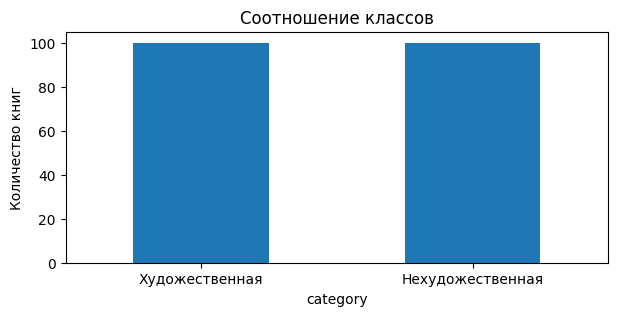

category
Художественная литература      100
Нехудожественная литература    100
Name: count, dtype: int64

In [8]:
counts = df['category'].value_counts()
counts.rename(index = {
    'Художественная литература': 'Художественная',
    'Нехудожественная литература': 'Нехудожественная'
}).plot(kind = 'bar', rot = 0, figsize = (7, 3))
plt.ylabel('Количество книг')
plt.title('Соотношение классов')
plt.show()

counts

## Часть 2. Предобработка текста

In [9]:
word_tokenizer = nltk.WordPunctTokenizer()
regex = re.compile(r'[А-Яа-яA-Za-zЁё]+')

def words_only(text, regex = regex):
    return ' '.join(regex.findall(text)).lower().replace('ё', 'е')

def process_data(data):
    texts = []
    for item in tqdm(data):
        text_lower = words_only(item['text'])
        tokens = word_tokenizer.tokenize(text_lower)
        texts.append(' '.join(tokens))
    return texts

In [10]:
df['clean_text'] = process_data(df.to_dict('records'))
print('Повторы описаний:', df['clean_text'].duplicated().sum())
df = df[df['clean_text'].ne('')].drop_duplicates(subset = 'clean_text').reset_index(drop = True)

texts = df['clean_text'].tolist()
y = df['category'].tolist()
print('Осталось книг:', len(texts))


  0%|          | 0/200 [00:00<?, ?it/s]


100%|██████████| 200/200 [00:00<00:00, 17422.91it/s]

Повторы описаний: 0
Осталось книг: 200


In [11]:
i = 1
print('Категория:', y[i])
print('Текст:', texts[i][:700])

Категория: Художественная литература
Текст: он художник и создан чтобы служить свету но вынужден гнаться за тенью в чужом сумрачном мире его прошлое ложь настоящее лабиринт загадок ему встречаются демоны смельчаки рыцари и каждый хранит тайну порой даже не одну чтобы приблизиться к цели герою предстоит одолеть череду испытаний в угоду чужим интересам постичь собственную природу разобраться в своих чувствах и поступиться ими спотыкаться и подниматься вновь и в конце концов сделать выбор правильный ли пусть каждый решит для себя


In [12]:
def label2num(y):
    if y == 'Нехудожественная литература':
        return 1
    if y == 'Художественная литература':
        return 0

encoded_y = [label2num(yy) for yy in y]

## Train/test

In [13]:
from sklearn.model_selection import train_test_split

train_texts, test_texts, train_y, test_y = train_test_split(
    texts, encoded_y, test_size = 0.25, random_state = 42, stratify = encoded_y
)

print('Train:', len(train_texts))
print('Test:', len(test_texts))

Train: 150
Test: 50


## TF-IDF

In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer

stop_words = sorted(set(word.replace('ё', 'е') for word in saved_result['stop_words']))
vectorizer = TfidfVectorizer(
    ngram_range = (1, 2), stop_words = stop_words,
    min_df = 2, max_df = 0.9, norm = None
)

train_X = vectorizer.fit_transform(train_texts)
test_X = vectorizer.transform(test_texts)

print(train_X.shape, test_X.shape)
vectorizer.get_feature_names_out()[:10]

(150, 1519) (50, 1519)


array(['book', 'ii', 'in', 'new', 'new yorker', 'the', 'the new', 'xix',
       'xix xx', 'xix века'], dtype=object)

## Обучение логистической регрессии

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold

model = Pipeline([
    ('vectorizer', vectorizer),
    ('clf', LogisticRegression(
        solver = 'liblinear', class_weight = 'balanced', max_iter = 2000, random_state = 42
    ))
])

cv = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 42)
search = GridSearchCV(
    model, {'clf__C': np.logspace(-4, 2, 7)},
    scoring = 'f1_macro', cv = cv, n_jobs = 1, error_score = 'raise'
)
search.fit(train_texts, train_y)

print('Лучший C:', search.best_params_['clf__C'])
print('CV F1 macro:', round(search.best_score_, 3))

Лучший C: 1.0
CV F1 macro: 0.893


In [16]:
cv_results = pd.DataFrame(search.cv_results_)
cv_results[['param_clf__C', 'mean_test_score', 'std_test_score', 'rank_test_score']]

,param_clf__C,mean_test_score,std_test_score,rank_test_score
0,0.0001,0.835972,0.040881,7
1,0.0010,0.864117,0.061777,6
2,0.0100,0.879058,0.078640,4
3,0.1000,0.885898,0.078500,3
4,1.0000,0.892857,0.068290,1
5,10.0000,0.886317,0.077852,2
6,100.0000,0.872834,0.064653,5


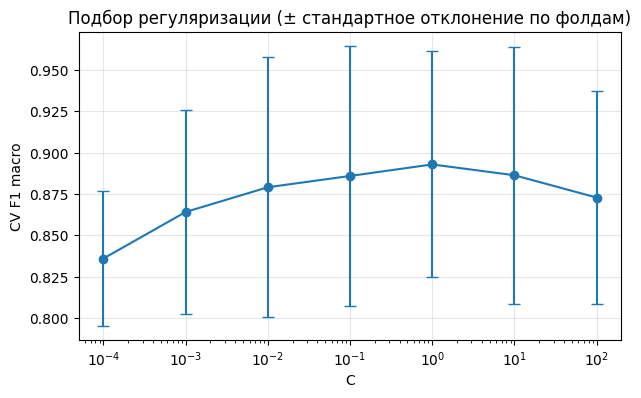

In [17]:
plt.figure(figsize = (7, 4))
plt.errorbar(
    cv_results['param_clf__C'].astype(float), cv_results['mean_test_score'],
    yerr = cv_results['std_test_score'], marker = 'o', capsize = 4
)
plt.xscale('log')
plt.xlabel('C')
plt.ylabel('CV F1 macro')
plt.title('Подбор регуляризации (± стандартное отклонение по фолдам)')
plt.grid(alpha = 0.3)
plt.show()

## Оценка качества

Сравнить с моделью, всегда предсказывающей самый частый класс.
Основная метрика — macro F1: она одинаково учитывает оба класса.
Для ROC AUC положительный класс — `Нехудожественная литература`.

In [18]:
vectorizer = search.best_estimator_.named_steps['vectorizer']
clf = search.best_estimator_.named_steps['clf']
train_X = vectorizer.transform(train_texts)
test_X = vectorizer.transform(test_texts)

pred = clf.predict(test_X)
proba = clf.predict_proba(test_X)[:, 1]

print('Предсказанные метки:', pred[:20])
print('Истинные метки:', test_y[:20])

Предсказанные метки: [1 1 1 0 1 0 0 1 1 1 1 1 1 1 1 1 0 0 1 0]
Истинные метки: [1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0]


In [19]:
from sklearn.dummy import DummyClassifier

dummy = DummyClassifier(strategy = 'most_frequent')
dummy.fit(train_X, train_y)
dummy_pred = dummy.predict(test_X)
dummy_proba = dummy.predict_proba(test_X)[:, 1]

metrics = pd.DataFrame({
    'Accuracy': [accuracy_score(test_y, dummy_pred), accuracy_score(test_y, pred)],
    'F1 macro': [f1_score(test_y, dummy_pred, average = 'macro'), f1_score(test_y, pred, average = 'macro')],
    'ROC AUC': [roc_auc_score(test_y, dummy_proba), roc_auc_score(test_y, proba)]
}, index = ['Самый частый класс', 'Логистическая регрессия'])
metrics.round(3)

,Accuracy,F1 macro,ROC AUC
Самый частый класс,0.50,0.333,0.500
Логистическая регрессия,0.94,0.940,0.963


                  precision    recall  f1-score   support

  Художественная      1.000     0.880     0.936        25
Нехудожественная      0.893     1.000     0.943        25

        accuracy                          0.940        50
       macro avg      0.946     0.940     0.940        50
    weighted avg      0.946     0.940     0.940        50



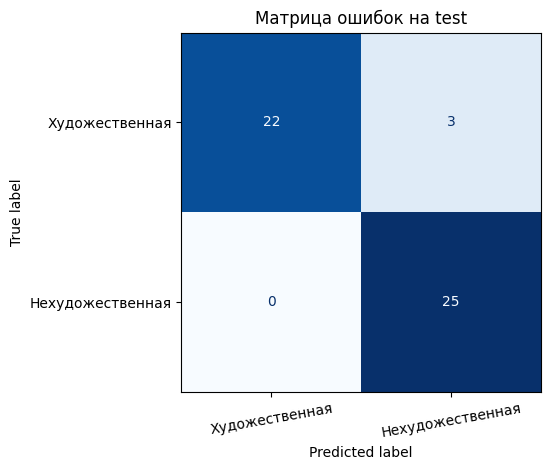

In [20]:
labels = ['Художественная', 'Нехудожественная']
print(classification_report(test_y, pred, target_names = labels, digits = 3))

ConfusionMatrixDisplay.from_predictions(
    test_y, pred, display_labels = labels, cmap = 'Blues', colorbar = False,
    xticks_rotation = 10
)
plt.title('Матрица ошибок на test')
plt.tight_layout()
plt.show()

In [21]:
def num2label(y):
    return 'Нехудожественная литература' if y == 1 else 'Художественная литература'

for i in range(3):
    print('Истинный класс:', num2label(test_y[i]))
    print('Предсказанный класс:', num2label(pred[i]))
    print('Текст:', test_texts[i][:350] + '...')
    print()

Истинный класс: Нехудожественная литература
Предсказанный класс: Нехудожественная литература
Текст: очередная прогулка по переулкам старой москвы начнется с района легендарных патриарших прудов по часовой стрелке мы отправимся в путешествие от малой никитской улицы и пройдемся до тверской а затем по старым воротникам дойдем сначала до малой дмитровки а потом и до большой и побродим в шубино и глинищах снова свернем к тверской и через успенский вр...

Истинный класс: Нехудожественная литература
Предсказанный класс: Нехудожественная литература
Текст: вашему вниманию предлагается книга серии практическая психология быстрое восстановление здоровья эффективная методика по устранению страха стресса и болезней она принадлежит перу известного врача и психолога хасая алиева автора уникального метода ключ позволяющего за короткий период вывести человека из стрессового состояния этот метод основан на ин...

Истинный класс: Нехудожественная литература
Предсказанный класс: Нехудожественная литерату

## Коэффициенты регрессии (топ-50)

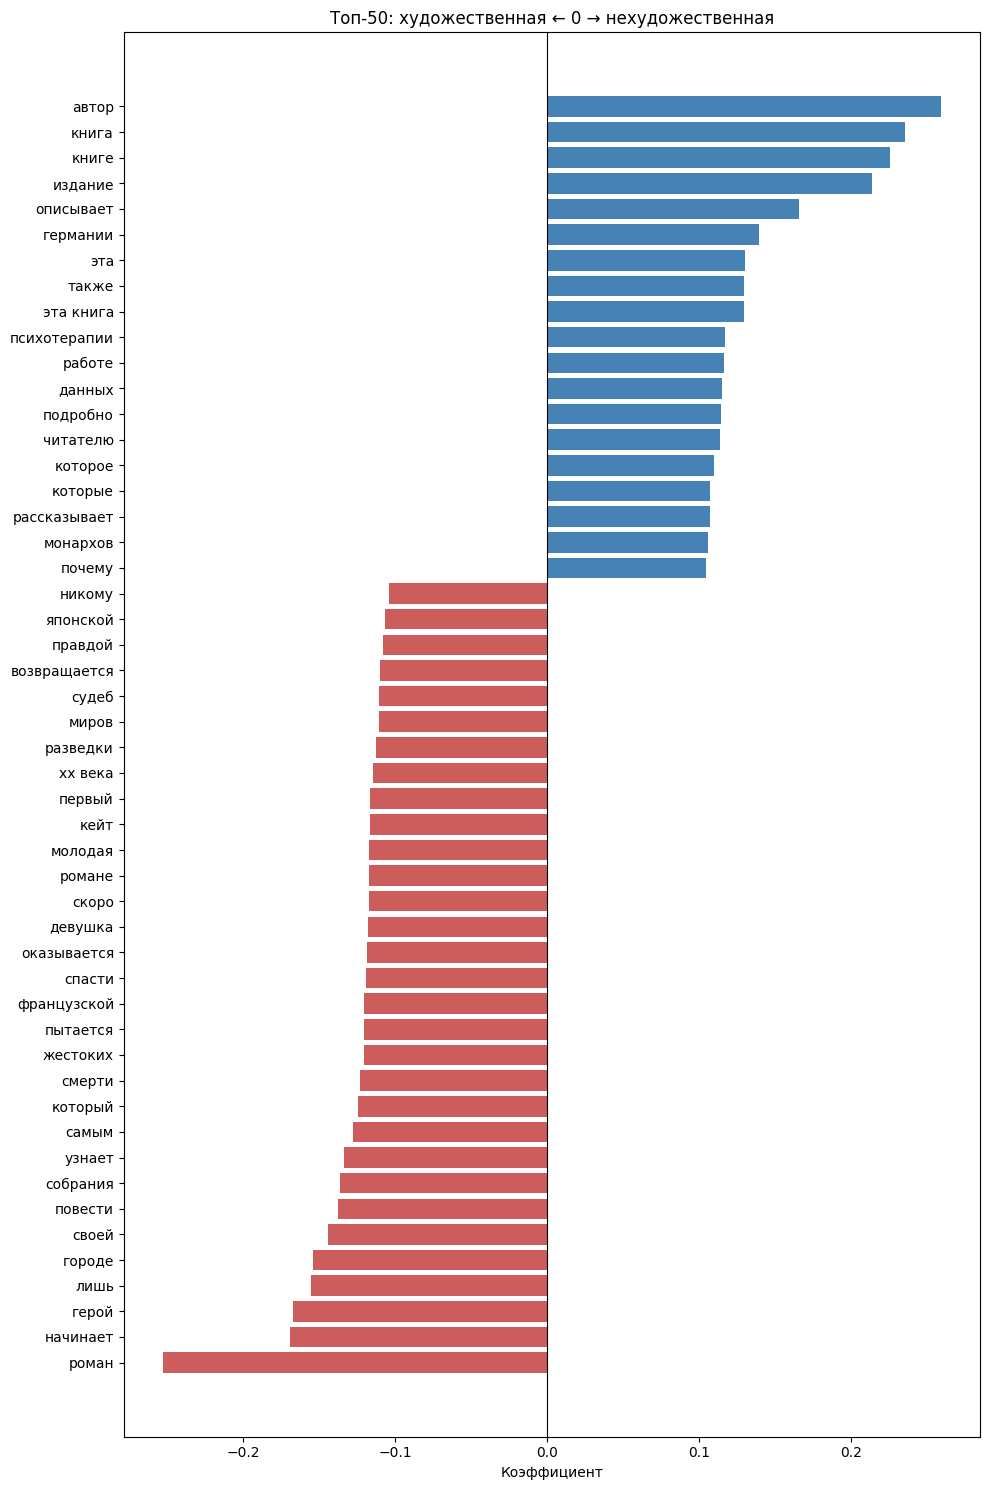

In [22]:
coefficients = pd.DataFrame({
    'word': vectorizer.get_feature_names_out(),
    'coefficient': clf.coef_[0]
})
top_words = coefficients.loc[coefficients['coefficient'].abs().nlargest(50).index]
top_words = top_words.sort_values('coefficient')

colors = np.where(top_words['coefficient'] > 0, 'steelblue', 'indianred')
plt.figure(figsize = (10, 15))
plt.barh(top_words['word'], top_words['coefficient'], color = colors)
plt.axvline(0, color = 'black', linewidth = 0.8)
plt.xlabel('Коэффициент')
plt.title('Топ-50: художественная ← 0 → нехудожественная')
plt.tight_layout()
plt.show()

In [23]:
print('В сторону нехудожественной литературы:')
print(coefficients.nlargest(10, 'coefficient').to_string(index = False))
print('\nВ сторону художественной литературы:')
print(coefficients.nsmallest(10, 'coefficient').to_string(index = False))

В сторону нехудожественной литературы:
        word  coefficient
       автор     0.259278
       книга     0.235647
       книге     0.225477
     издание     0.213901
   описывает     0.166044
    германии     0.139265
         эта     0.130438
       также     0.129759
   эта книга     0.129517
психотерапии     0.116781

В сторону художественной литературы:
    word  coefficient
   роман    -0.253064
начинает    -0.169142
   герой    -0.167498
    лишь    -0.155564
  городе    -0.153999
   своей    -0.144399
 повести    -0.137451
собрания    -0.136344
  узнает    -0.134022
   самым    -0.127798


## Выводы

С «Лабиринта» собраны 200 русскоязычных аннотаций: 100 художественных и 100 нехудожественных книг.
Ошибок парсинга, пропусков и повторов описаний нет. Категории подтверждены в карточках книг.
В train попали 150 книг, в test — 50. Лучший `C = 1`, средний macro F1 на CV — 0.893.

На test получены Accuracy = 0.940, macro F1 = 0.940 и ROC AUC = 0.963.
У предсказания одного класса Accuracy = 0.500 и macro F1 = 0.333.
Модель правильно определила 47 из 50 книг: 22 художественные и все 25 нехудожественных.
Три художественные книги были отнесены к нехудожественным.

Слова `роман`, `герой`, `повести`, `узнает` смещают предсказание к художественной литературе:
они встречаются в описаниях сюжетов и персонажей. `автор`, `издание`, `описывает`, `психотерапии`
и биграмма `эта книга` смещают предсказание к нехудожественной литературе.
Модель различает и тематику книг, и стиль аннотаций. Например, `книга` само по себе не определяет жанр,
но в этой выборке связано с нехудожественным классом. Коэффициенты относятся к словоформам;
лемматизация не применялась. При фиксированных остальных признаках положительный коэффициент
увеличивает логарифм шансов класса 1, отрицательный — уменьшает.